# Analysis of membrane sweeling and cracking based on ML segmentation

TODO:
    
- [x] load EC data
- [x] load segmented data
- [x] fetch physical time of images from registered data
- [ ] segment all samples
- [ ] define cropping for each sample
    - registered data as refrence
    - look up cropping for segmentation
    - [x] update ML code to include this cropping [:, 250:-250, 50:-50] was used for membrane of sample 3II
- [ ] find useful metric and employ
    - [ ] delaminated area
    - [x] crack volume
    - [x] membrane volume
    - [x] vs. charge, current
    - [ ] normalized metric
- [ ] continue from there

In [1]:
# modules

import json
import os
import socket
host = socket.gethostname()   
import scipy as sp
import scipy.ndimage
import scipy.optimize
import xarray as xr
import numpy as np
import matplotlib.pyplot as plt
from joblib import Parallel, delayed
import cupy as cp
import cucim
import warnings
import skimage
import skimage.morphology
import cupyx.scipy.ndimage as GPUndimage
GPUball = cucim.skimage.morphology.ball
ball = skimage.morphology.ball
import dask
import dask.array
import imageio
import matplotlib as mpl

# paths
if host == 'mpc2959.psi.ch':
    gitpath = '/mpc/homes/fische_r/lib/co2ely-tomcat'
    toppath = '/mpc/homes/fische_r/NAS/DASCOELY'
    toppathSSD = '/mnt/SSD/fische_r/COELY'

elif host == 'mpc2053.psi.ch':
    gitpath = '/mpc/homes/fische_r/lib/co2ely-tomcat'
    toppath = '/mpc/homes/fische_r/NAS/DASCOELY'
    toppathSSD = '/mpc/homes/fische_r/NAS/DASCOELY/processing'
else:
    print(host+' is not known to the notebook')
    
cwd = os.getcwd()
os.chdir(os.path.join(gitpath, 'EC_lab'))   
from plot_EC_lab_data import load_sample_data, plot_vs_time, plot_HFR_time_color, mpr_to_xr, HFR_color_plot_to_axis
os.chdir(cwd)


EC_path = os.path.join(toppath, 'EC_lab_files')

overview = json.load(open(os.path.join(gitpath, 'meta_and_linking_data','data_overview.json'), 'r'))
    
segmentation_path = os.path.join(toppath, 'processing', '04_membrane_ML')
registered_path = os.path.join(toppathSSD, '02_registered_3p1D')

px = 2.75e-6
vx = px**3

In [2]:
# fetch githash
import subprocess
cwd = os.getcwd()
os.chdir(gitpath)
git_sha = subprocess.check_output(['git', 'rev-parse', '--short', 'HEAD']).decode().strip()
githash = subprocess.check_output(['git', 'rev-parse', 'HEAD']).decode().strip()
os.chdir(cwd)

In [3]:
from mpl_toolkits.axes_grid1 import make_axes_locatable
from mpl_toolkits.axes_grid1.anchored_artists import AnchoredSizeBar
import matplotlib.font_manager as fm
fontprops = fm.FontProperties(size=14)

## Experiment with data

In [4]:
sample = '3II'
segpath = os.path.join(segmentation_path, sample, sample+'membrane_segmentation.nc')
seg_data = xr.load_dataset(segpath)

In [5]:
regpath = os.path.join(registered_path, '02_'+sample+'_registered_3p1D.nc')
reg_data = xr.open_dataset(regpath)
[ar,br,cr,dr,er,fr] = seg_data.attrs['05_ML_cropping']
images = [im for im in reg_data.keys() if im[3:7] == 'imag']
images.sort()

In [6]:
t_utc_tomo = reg_data['t_utc'].data

In [7]:
reg_data.close()

### crop the volume to exclude borders with errors

In [8]:
im = seg_data['segmented'].sel(timestep = 10)

In [9]:
# # crop = 50 for a,b seems reasonable


# crops = np.arange(0, 300, 20)
# volume = np.zeros(len(crops))
# im_size = volume.copy()

# for i in  range(len(crops)):
#     crop = crops[i]
#     a = 0+crop
#     b = im.shape[0]-crop
#     c = 0
#     d = im.shape[1]
#     e = 0 + crop
#     f = im.shape[2]-crop
    
#     volume[i] = np.count_nonzero(im[a:b,c:d,e:f]==0)
#     im_size[i] = (b-a)*(d-c)*(f-e)


In [10]:
# volume_old = volume.copy()
# im_size_old = im_size.copy()
# crops_old = np.arange(/0,200,10)

In [11]:
# plt.plot(crops, np.gradient(volume)/np.gradient(im_size))

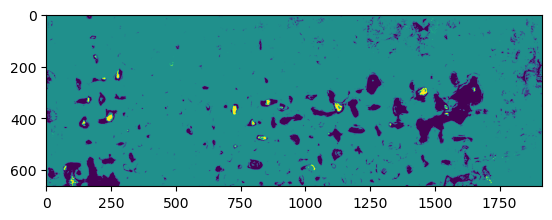

In [12]:
plt.imshow(im[50:-50,100,:])

In [13]:
reg_im = reg_data[list(reg_data.keys())[20]].data

In [14]:
reg_data.close()

In [15]:
cropx = 50  #:, 250:-250, 50:-50]

# initial cropping from registered data to segmented data
# for the other samples, get this information from the seg_data
# ar = 0
# br = 0
# cr = 250
# dr = -250+1
# er = 50
# fr = -50

[ar,br,cr,dr,er,fr] = seg_data.attrs['05_ML_cropping']

a1 = cropx
b1 = -cropx
c1 = 0
d1 = -1
e1 = 150
f1 = -250

a = a1 + ar
b = b1 + br
c = c1 + cr
d = d1 + dr
e = e1 + er 
f = f1 + fr

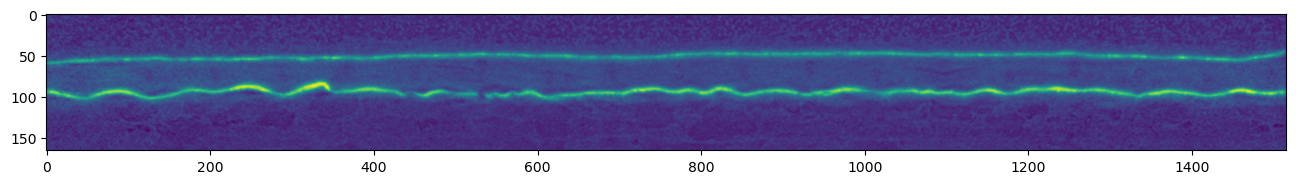

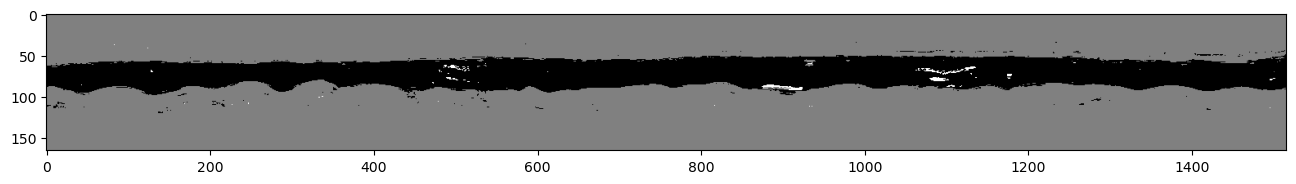

In [16]:
plt.figure(figsize=(16,9))
plt.imshow(reg_im[a+200,c:d,e:f])
plt.figure(figsize=(16,9))
plt.imshow(im[a1+200,c1:d1,e1:f1], cmap='gray')

In [17]:
seg_data.close()

### use morphology operation to remove segmentation noise

In [18]:
membrane_im = im[a1:b1,c1:d1,e1:f1]==0
crack_im = im[a1:b1,c1:d1,e1:f1]==2

In [19]:
def clean_binary_image(im, minsize = 200, fp_radius = 1, i=0, GPU = True):
    # GPU?
    if GPU:
        warnings.filterwarnings("ignore") #ignore numpy whining and spamming nan-warnings, inside function because joblib spawns workers with default settings on warnings?!   
        gpu_id = i%5 # i%4+1 uses gpus 1 through 4, leaving the big A40 (0) alone or i%5 to use all 5

        with cp.cuda.Device(gpu_id):
            im = cp.array(im)
            im = cucim.skimage.morphology.binary_opening(im, footprint=cucim.skimage.morphology.ball(fp_radius))
            im = cucim.skimage.morphology.remove_small_objects(im, min_size=minsize)
            im = cp.asnumpy(im)
            mempool = cp.get_default_memory_pool()
            mempool.free_all_blocks()
        
    else: 
        im = sp.ndimage.binary_opening(im, structure=skimage.morphology.ball(fp_radius))
        im = skimage.morphology.remove_small_objects(im, min_size=minsize)
        
    return im


def clean_and_count_binary_image(im, minsize = 200, fp_radius = 1, i=0, GPU = True):
    # GPU?
    if GPU:
        warnings.filterwarnings("ignore") #ignore numpy whining and spamming nan-warnings, inside function because joblib spawns workers with default settings on warnings?!   
        gpu_id = i%5 # i%4+1 uses gpus 1 through 4, leaving the big A40 (0) alone or i%5 to use all 5

        with cp.cuda.Device(gpu_id):
            im = cp.array(im)
            im = cucim.skimage.morphology.binary_opening(im, footprint=cucim.skimage.morphology.ball(fp_radius))
            im = cucim.skimage.morphology.remove_small_objects(im, min_size=minsize)
            count = cp.count_nonzero(im)
            count = cp.asnumpy(count) #that necessary?
            im = cp.asnumpy(im)
            mempool = cp.get_default_memory_pool()
            mempool.free_all_blocks()
        
    else: 
        im = sp.ndimage.binary_opening(im, structure=skimage.morphology.ball(fp_radius))
        im = skimage.morphology.remove_small_objects(im, min_size=minsize)
        count = np.count_nonzero(im)
        
    return im, count

### extract volumes of crack and membrane
compare in second step to "cleaned" images

In [20]:
def clean_4D_image(im4D, minsize = 20, fp_radius = 1, GPU = True):
    results = Parallel(n_jobs = 10)(delayed(clean_binary_image)(im4D[:,:,:,i], minsize, fp_radius,i, GPU) for i in range(im4D.shape[3]))
    clean4D = np.stack(results, axis=3)
    return clean4D

def clean_and_count_4D_image(im4D, minsize = 20, fp_radius = 1, GPU = True):
    results = Parallel(n_jobs = 10)(delayed(clean_and_count_binary_image)(im4D[:,:,:,i], minsize, fp_radius,i, GPU) for i in range(im4D.shape[3]))
    vols = [result[1] for result in results]
    ims = [result[0] for result in results]
    clean4D = np.stack(ims, axis=3)
    vols = np.stack(vols)
    return clean4D, vols


def extract_membrane_and_crack_volume(seg_data):
    membrane = seg_data['segmented'][a1:b1,c1:d1,e1:f1,:]==0
    crack = seg_data['segmented'][a1:b1,c1:d1,e1:f1,:]==2
    
    
    membrane_vol = np.count_nonzero(membrane, axis=(0,1,2))
    crack_vol = np.count_nonzero(crack, axis=(0,1,2))
    return membrane_vol, crack_vol

def ectract_delaminated_area(seg_data):
    #binary project image on xz-plane and count (xy roughly membrane plamne)
    return crack_area



In [21]:
mem_clean, mem_vol_clean = clean_and_count_4D_image(seg_data['segmented'][a1:b1,c1:d1,e1:f1,:]==0, GPU=False)

In [22]:
crack_clean, crack_vol_clean = clean_and_count_4D_image(seg_data['segmented'][a1:b1,c1:d1,e1:f1,:]==2, GPU=False)

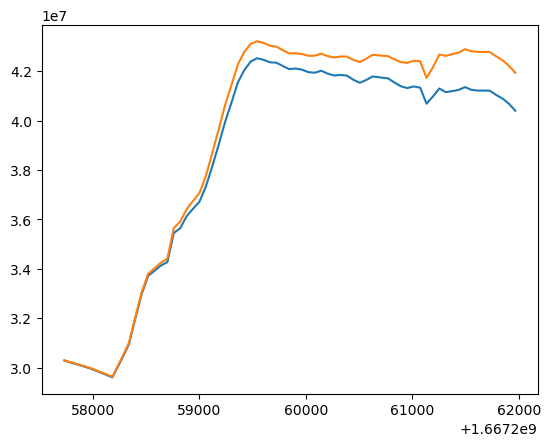

In [23]:
plt.plot(t_utc_tomo, mem_vol_clean)
plt.plot(t_utc_tomo, crack_vol_clean+mem_vol_clean)

### delaminated area

In [24]:
mem_clean.shape

(663, 166, 1516, 63)

In [25]:
delam_area = crack_clean.any(axis=1)

In [26]:
delam_area.shape

(663, 1516, 63)

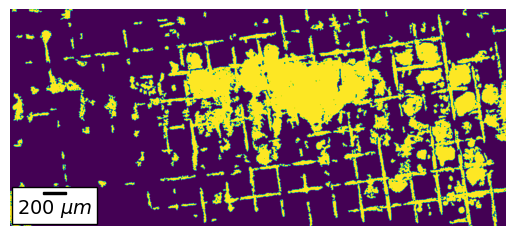

In [27]:
fig, ax = plt.subplots()

ax.imshow(delam_area[:,:,-1])
ax.axis('off')
scalebar = AnchoredSizeBar(ax.transData,
                           200/2.75, '200 $\mu m$', 'lower left', 
                           pad=0.25,
                           color='black',
                           frameon=True,
                           size_vertical=8,
                           fontproperties=fontprops)
ax.add_artist(scalebar)
plt.gca().xaxis.set_major_locator(plt.NullLocator())
plt.gca().yaxis.set_major_locator(plt.NullLocator())

In [28]:
# for ts in range(delam_area.shape[-1]):

#     fig, ax = plt.subplots()

#     ax.imshow(delam_area[:,:,ts])
#     ax.axis('off')
#     scalebar = AnchoredSizeBar(ax.transData,
#                                200/2.75, '200 $\mu m$', 'lower left', 
#                                pad=0.25,
#                                color='black',
#                                frameon=True,
#                                size_vertical=8,
#                                fontproperties=fontprops)
#     ax.add_artist(scalebar)
#     plt.gca().xaxis.set_major_locator(plt.NullLocator())
#     plt.gca().yaxis.set_major_locator(plt.NullLocator())
#     # plt.savefig(os.path.join(toppath, 'plots', 'test_videos', '3II_gas_area', 'delam_area_'+str(ts)+'.png'), bbox_inches='tight')
#     plt.close()

In [29]:
delam_cross2 = crack_clean.any(axis=2)

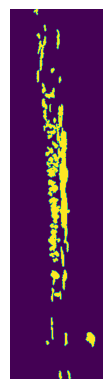

In [30]:
fig, ax = plt.subplots()

ax.imshow(delam_cross2[:,:,10])
ax.axis('off')
scalebar = AnchoredSizeBar(ax.transData,
                           200/2.75, '200 $\mu m$', 'lower left', 
                           pad=0.25,
                           color='black',
                           frameon=True,
                           size_vertical=8,
                           fontproperties=fontprops)
# ax.add_artist(scalebar)
plt.gca().xaxis.set_major_locator(plt.NullLocator())
plt.gca().yaxis.set_major_locator(plt.NullLocator())

In [252]:
for ts in range(delam_area.shape[-1]):

    fig, ax = plt.subplots()

    ax.imshow(delam_cross2[:,:,ts])
    ax.axis('off')
    scalebar = AnchoredSizeBar(ax.transData,
                               200/2.75, '200 $\mu m$', 'lower left', 
                               pad=0.25,
                               color='black',
                               frameon=True,
                               size_vertical=8,
                               fontproperties=fontprops)
    # ax.add_artist(scalebar)
    plt.gca().xaxis.set_major_locator(plt.NullLocator())
    plt.gca().yaxis.set_major_locator(plt.NullLocator())
    plt.savefig(os.path.join(toppath, 'plots', 'test_videos', '3II_gas_cross2', 'delam_cross2_'+str(ts)+'.png'), bbox_inches='tight')
    plt.close()

In [31]:
toppath

'/mpc/homes/fische_r/NAS/DASCOELY'

In [32]:
delam_count = np.count_nonzero(delam_area, axis = (0,1))

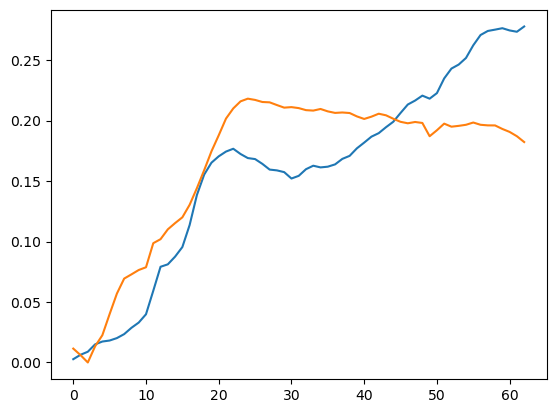

In [33]:
plt.plot(delam_count/delam_area.shape[0]/delam_area.shape[1])
plt.plot((mem_vol_clean/mem_vol_clean.min()-1)/2)

### load EC and compare

In [34]:
# normalize data versus mormalized charg
def get_principal_data(ECdata):
    dims = np.array([ECdata[i].dims['t'] for i in range(len(ECdata))])
    # print(dims)
    I = np.zeros(dims.sum())
    timestamps = I.copy()
    E = I.copy()
    Re = I.copy()
    Im = I.copy()
    # print(len(dims))

    I[:dims[0]] = ECdata[0]['I'].data
    # timestamps[:dims[0]] = ECdata[0]['t'].data
    timestamps[:dims[0]] = ECdata[0]['timestamp (utc)'].data
    E[:dims[0]] = ECdata[0]['$E_{we}$'].data
    Im[:dims[0]] = ECdata[0]['-Im(Z)'].data
    Re[:dims[0]] = ECdata[0]['Re(Z)'].data

    for i in range(1,len(dims)):
        I[dims[:i].sum():dims[:i].sum()+dims[i]] = ECdata[i]['I'].data
        timestamps[dims[:i].sum():dims[:i].sum()+dims[i]] = ECdata[i]['timestamp (utc)'].data
        # timestamps[dims[i-1]:dims[i-1]+dims[i]] = ECdata[i]['t'].data +ECdata[i-1]['t'].data.max()
        E[dims[:i].sum():dims[:i].sum()+dims[i]] = ECdata[i]['$E_{we}$'].data
        Im[dims[:i].sum():dims[:i].sum()+dims[i]] = ECdata[i]['-Im(Z)'].data
        Re[dims[:i].sum():dims[:i].sum()+dims[i]] = ECdata[i]['Re(Z)'].data
    
    order = timestamps.argsort()
    t0 = timestamps[timestamps>0].min()
    # print(t0)
    I = I[order]
    E = E[order]
    Im = Im[order]
    Re = Re[order]
    timestamps = timestamps[order]
    # print(timestamps[0])
    
#     filter out potential overflow cases
    I = I[E>-5]
    Im = Im[E>-5]
    Re = Re[E>-5]
    timestamps = timestamps[E>-5]
    E = E[E>-5]
    
    time = timestamps - t0
    dt = np.gradient(time)
    Q = np.cumsum(-I*dt)
    return Q, I, E, time, Im, Re, timestamps, t0

In [35]:
ECdata = load_sample_data(sample, overview, EC_path)
Q, I, E, time, Im, Re, timestamps, t0 = get_principal_data(ECdata)

In [36]:
Qfun = sp.interpolate.interp1d(timestamps, Q, fill_value=np.nan, bounds_error=False)
Ifun = sp.interpolate.interp1d(timestamps, I, fill_value=np.nan, bounds_error=False)

### crack 

In [37]:
crack_clean.shape

(663, 166, 1516, 63)

(-10.0, 60.0)

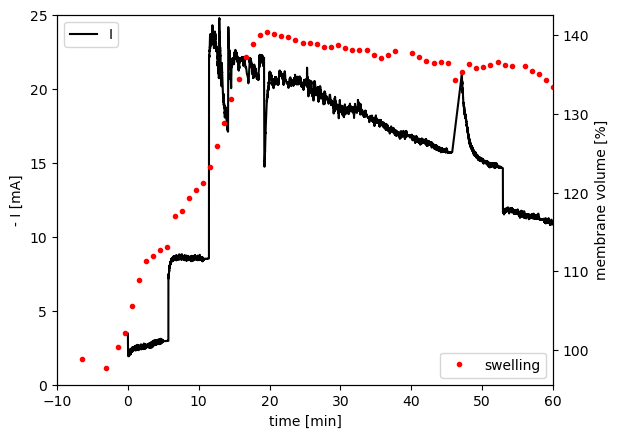

In [38]:
fig, ax = plt.subplots()
ax.plot((timestamps-t0)/60, -I, 'k', label='I')
ax2 = ax.twinx()
# ax2.plot((t_utc_tomo-t0)/60, 100-delam_count/crack_clean.shape[0]/crack_clean.shape[2]*100, 'r.', label='intact area')
# ax2.plot((t_utc_tomo-t0)/60, (mem_vol_clean/mem_vol_clean.min()-1)*100, 'b.', label='swelling')
# ax2.plot((t_utc_tomo-t0)/60, (crack_vol_clean/crack_vol_clean.max())*100, 'g.', label='rel. gas volume')
# ax2.plot((t_utc_tomo-t0)/60, delam_count/delam_count.max()*100, 'rx', label='rel. damaged area')
ax2.plot((t_utc_tomo-t0)/60, (mem_vol_clean/mem_vol_clean[0])*100, 'r.', label='swelling')

ax.set_ylim(0,25)
# ax2.set_ylim(4.05e7,4.2e7)
# ax.set_yscale('log')
# ax2.set_yscale('log')
ax.set_xlabel('time stamp [s]')
ax.set_xlabel('time [min]')
ax.set_ylabel('- I [mA]')
# ax2.set_ylim(0,100)
ax2.set_ylabel('value [%]')
ax2.set_ylabel('membrane volume [%]')
ax.legend(loc = 'upper left')
ax2.legend(loc = 'lower right')
ax.set_xlim(-10,60)

## Test stack

## Deconvolute CL damage and membrane delamination
### Observation
- Pockets of gas between CL and membrane count to delaminated area
- Segmentation does not count them anymore when CL piece is broken off the top of the gas pocket
- small gas bubbles appear and dissappear
- fiber delamination along entire fiber forming a connected netwerk
- smaller bubbles are drained once a big crack appear elsewhere in the membrane

In [39]:
CLarea_diff_scan = xr.load_dataset(os.path.join(toppath, 'processing',  '06_anode_CL', sample+'_CLarea_holes_1dadfb8.nc'))['CL_damaged_area'].data

In [40]:
seg_data

<xarray.Dataset>
Dimensions:    (x: 763, y: 167, z: 1916, timestep: 63, feature: 110)
Coordinates:
  * x          (x) int64 0 1 2 3 4 5 6 7 8 ... 755 756 757 758 759 760 761 762
  * y          (y) int64 0 1 2 3 4 5 6 7 8 ... 159 160 161 162 163 164 165 166
  * z          (z) int64 0 1 2 3 4 5 6 7 ... 1909 1910 1911 1912 1913 1914 1915
  * timestep   (timestep) int64 0 1 2 3 4 5 6 7 8 ... 54 55 56 57 58 59 60 61 62
  * feature    (feature) object 'diff_to_first_' ... 'full_temp_min_Gauss_2.0'
Data variables:
    segmented  (x, y, z, timestep) uint8 1 1 1 1 1 1 1 1 1 ... 1 1 1 1 1 1 1 1 1
    t_utc      (timestep) float64 1.667e+09 1.667e+09 ... 1.667e+09 1.667e+09
    time       (timestep) float64 6.429 48.37 13.46 15.85 ... 122.4 182.6 242.8
Attributes: (12/26)
    name:                                              3II
    voxel size:                                        2.75 um
    voxel:                                             2.75e-06
    post rotation cropping coordinates [a:b,c:d,e:f]:  [   5  769   20  687  ...
    rotation angle 1:                                  -1.15
    rotation angle 2:                                  -1.15
    ...                                                ...
    07_crop_githash:                                   566fb36820c8cea5d71272...
    git_sha_registration:                              612e92b
    githash_registration:                              612e92b28895745f6b422c...
    05_ML_cropping:                                    [   0   -1  250 -250  ...
    pytrain_git:                                       693a41f
    05_coely_gitsha:                                   2d0f549

In [41]:
CLA = CLarea_diff_scan.copy()

In [42]:
t_tomo = t_utc_tomo - t0

In [43]:
ts_tomo_op = np.argmin(np.abs(t_tomo-11.5*60))
CLA_calib2 = np.nanmean(CLA[ts_tomo_op-1:ts_tomo_op+2])
CLA = CLA-CLA_calib2 

In [44]:
DLA = delam_count.copy()
DLA_calib2 = np.nanmean(DLA[ts_tomo_op-1:ts_tomo_op+2])
DLA = DLA-DLA_calib2 

In [45]:
test = xr.open_dataset(os.path.join(toppath, 'processing',  '06_anode_CL', '06_'+sample+'_anode_CL_segmented_filtered.nc'))
basearea = test['segmented'].shape[0]*test['segmented'].shape[2]
test.close()

In [46]:
baseareaML = seg_data['segmented'][a1:b1,c1:d1,e1:f1,:].shape[0]*seg_data['segmented'][a1:b1,c1:d1,e1:f1,:].shape[2]

In [47]:
baseareaML/basearea

0.6525726128147594

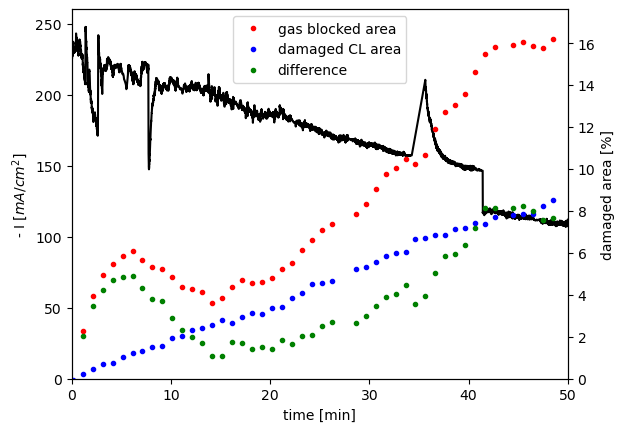

In [48]:
fig, ax = plt.subplots()
ax.plot((timestamps-t0)/60-11.5, -I/.1, 'k', label='I')
# ax.plot((timestamps-t0)/60-11.5, 100*I/12.5+200, 'k', label='I')
ax2 = ax.twinx()
ax2.plot(t_tomo/60-11.5, DLA/baseareaML*100, 'r.', label = 'gas blocked area')
ax2.plot(t_tomo/60-11.5, CLA/basearea*100, 'b.', label = 'damaged CL area')
ax2.plot(t_tomo/60-11.5, DLA/baseareaML*100 - CLA/basearea*100, 'g.', label = 'difference')

# ax2.plot(t_tomo/60-11.5, (mem_vol_clean/mem_vol_clean.min()-1)*100, 'kx', label='swelling')
# ax2.plot(t_tomo/60-11.5, (crack_vol_clean/crack_vol_clean.max())*100, 'rx', label='rel. gas volume')

ax.set_xlim(0,50)
ax.set_ylim(0)
# ax2.set_ylim(4.05e7,4.2e7)
# ax.set_yscale('log')
# ax2.set_yscale('log')
ax.set_xlabel('time [min]')
ax.set_ylabel('- I [$mA/cm^2$]')
ax2.set_ylim(0)
ax2.set_ylabel('damaged area [%]')
ax2.legend(loc = 'upper center')

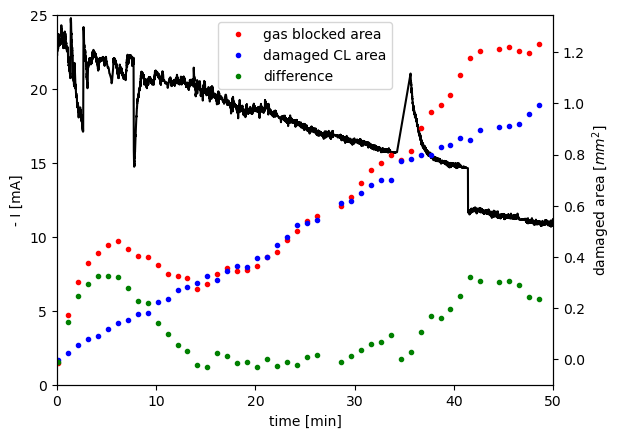

In [49]:
fig, ax = plt.subplots()
ax.plot((timestamps-t0)/60-11.5, -I, 'k', label='I')
ax2 = ax.twinx()
ax2.plot(t_tomo/60-11.5, DLA*(1000*px)**2, 'r.', label = 'gas blocked area')
ax2.plot(t_tomo/60-11.5, CLA*(1000*px)**2, 'b.', label = 'damaged CL area')
ax2.plot(t_tomo/60-11.5, DLA*(1000*px)**2 - CLA*(1000*px)**2, 'g.', label = 'difference')

ax.set_xlim(0,50)
ax.set_ylim(0,25)
# ax2.set_ylim(4.05e7,4.2e7)
# ax.set_yscale('log')
# ax2.set_yscale('log')
ax.set_xlabel('time [min]')
ax.set_ylabel('- I [mA]')
ax2.set_ylim(-0.1)
ax2.set_ylabel('damaged area [$mm^2$]')
ax2.legend(loc = 'upper center')

In [50]:
px

2.75e-06

### Check by overlay of CL holes and BPM segmentation

idea: segment CL, dilate and all contacting gas bubbles are then labeled as "CL gas"

In [51]:
ts = 20

In [52]:
segtest = seg_data['segmented'].sel(timestep = ts).data==2

In [53]:
rawtest = reg_data[images[ts]][ar:br,cr:dr,er:fr].data

#### Gauss-Blur and segmentation as for CL crumbling
is the segmented CL stored somewhere stored with a useful cropping? No, cropped to anode and cathode respectively <\br>
use dask for full 4D dataset

In [54]:
th = 15000
thmax = 3*th 

In [55]:
rawtest[rawtest>thmax] = 0
rawtest = skimage.filters.gaussian(rawtest, mode='nearest', sigma = 1, preserve_range=True)

In [56]:
CLtest = rawtest>th

#### label seperate objects of segmented cracks
better remove small objects first

In [59]:
ball = skimage.morphology.ball

def Gaussian_Blur_space(da, sigma):      
    deptharray = np.ones(da.ndim)+4*sigma
    deptharray[-1] = 0
    sigmas = np.ones(deptharray.shape)*sigma
    deptharray = tuple(np.min([deptharray, da.shape], axis=0))

    sigmas[-1] = 0
    G = da.map_overlap(skimage.filters.gaussian, depth=deptharray, boundary='nearest', sigma = sigmas, preserve_range=True)
    return G

def label_gas_cavities(im, imCL, GPU=True, i=0):
    warnings.filterwarnings("ignore") #ignore numpy whining and spamming nan-warnings, inside function because joblib spawns workers with default settings on warnings?!  
    
    im = clean_binary_image(im, i=i, GPU=GPU)
    
    if GPU:
        gpu_id = i%5 # i%4+1 uses gpus 1 through 4, leaving the big A40 (0) alone or i%5 to use all 5

        with cp.cuda.Device(gpu_id):
            im = cp.array(im)
            CLGPU = cp.array(imCL)
            imCL = GPUndimage.binary_dilation(imCL, GPUball(3))
            im = cucim.skimage.measure.label(im)
            labels, counts = cp.unique(im, return_counts=True)
            CLlabels = cp.unique(im[imCL])
            im = cp.asnumpy(im)
            labels = cp.asnumpy(labels)
            counts = cp.asnumpy(counts)
            CLlabels = cp.asnumpy(CLlabels)
            mempool = cp.get_default_memory_pool()
            mempool.free_all_blocks()

        
    else:
        imCL = sp.ndimage.binary_dilation(imCL, ball(3))
        im = skimage.measure.label(im)
        labels, counts = np.unique(im, return_counts=True)
        CLlabels = np.unique(im[imCL])
        
    return im, labels, counts, CLlabels

In [280]:
segtest = clean_binary_image(segtest)

In [281]:
label, label_ids, label_counts, CL_label_ids = label_gas_cavities(segtest)

TypeError: label_gas_cavities() missing 1 required positional argument: 'imCL'

#### apply to 4D

In [60]:
shp = seg_data['segmented'].shape
rawim = np.zeros(shp, dtype = np.uint16)
for i in range(shp[-1]):
    if i%10==0:
        print(i)
    rawim[...,i] = reg_data[images[i]][ar:br,cr:dr,er:fr].data

reg_data.close()

da = dask.array.from_array(rawim[20:-20,20:-20,250:1600])

0
10
20
30
40
50
60


In [61]:
da[da>thmax] = 0

In [62]:
rawim = Gaussian_Blur_space(da, 1)
rawim = da.compute()

In [63]:
CLim4D = rawim>th

In [64]:
del rawim
del da

In [65]:
def label_per_time_step(ts, CLim, im):
    label, label_ids, label_counts, CL_label_ids = label_gas_cavities(im, CLim, i=ts, GPU=False)
    totcav = label_counts[1:].sum()
    CLcav = label_counts[CL_label_ids-1].sum()
    BPMcav = totcav-CLcav
    
    return label, label_ids, label_counts, CL_label_ids, totcav, CLcav, BPMcav

In [66]:
# CLim4D = CLim4D[20:-20,20:-20,250:1600,:] #post cropping for sample 3II

In [67]:
# resultsold = results.copy()

In [68]:
CLim4D.shape

(723, 127, 1350, 63)

In [69]:
results = Parallel(n_jobs = 20)(delayed(label_per_time_step)(ts, CLim4D[...,ts], seg_data['segmented'].sel(timestep = ts)[20:-20,20:-20,250:1600].data==2) for ts in range(shp[-1])) #

In [70]:
results = resultsold 

NameError: name 'resultsold' is not defined

In [71]:
label4D = np.zeros(CLim4D.shape, dtype=np.uint16)

In [72]:
cav_vol = np.zeros(shp[-1])
CL_cav = np.zeros(shp[-1])

In [73]:
for i in range(shp[-1]):
    label4D[...,i] = results[i][0]
    cav_vol[i] = results[i][2][1:].sum()
    CL_cav[i] = results[i][2][1:][results[i][3][1:]-1].sum()
BPM_cav = cav_vol-CL_cav

(0.0, 1564770.6)

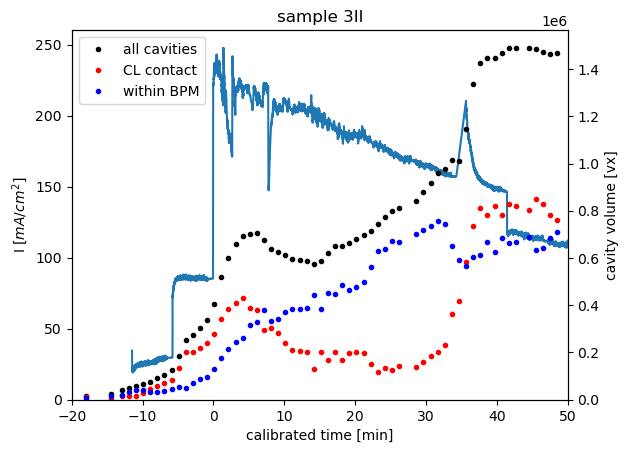

In [74]:
fig, ax  = plt.subplots()
ax2 = ax.twinx()
ax2.plot((t_utc_tomo-t0)/60-11.5,cav_vol,'k.', label='all cavities')
ax2.plot((t_utc_tomo-t0)/60-11.5,CL_cav, 'r.', label='CL contact')
ax2.plot((t_utc_tomo-t0)/60-11.5,BPM_cav, 'b.', label='within BPM')
# ax.plot((t_utc_tomo-t0)/60, (mem_vol_clean/mem_vol_clean.max()), 'r.', label='swelling')

# ax2.plot((t_utc_tomo-t0)/60-11.5,CL_cav3, '--', label='at CL')
# ax2.plot((t_utc_tomo-t0)/60-11.5,BPM_cav3, '--', label='in BPM')


# ax2.plot((t_utc_tomo-t0)/60-11.5,CL_cav4, '-.', label='at CL')
# ax2.plot((t_utc_tomo-t0)/60-11.5,BPM_cav4, '-.', label='in BPM')

ax2.legend()


ax.plot((timestamps-t0)/60-11.5, -I/.1,  label='I')
# plt.ylim(0,1E-12)
# plt.yscale('log')
ax.set_xlabel('calibrated time [min]')
ax.set_ylabel('I [$mA/cm^2$]')
ax2.set_ylabel('cavity volume [vx]')
plt.title('sample '+sample)
ax.set_xlim(-20,50)
ax.set_ylim(0)
ax2.set_ylim(0)

(0.0, 2000000.0)

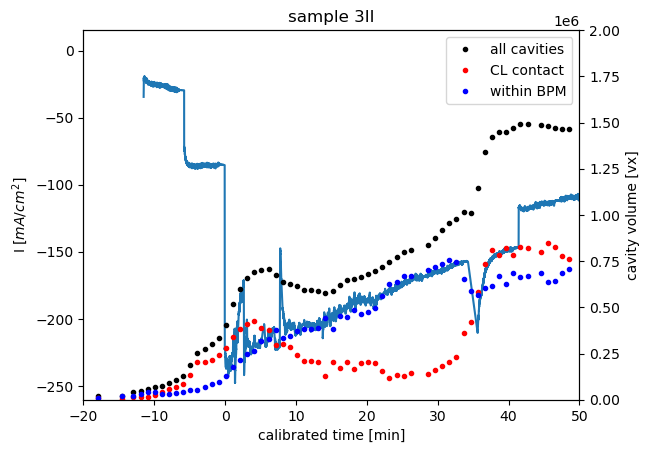

In [75]:
fig, ax  = plt.subplots()
ax2 = ax.twinx()
ax2.plot((t_utc_tomo-t0)/60-11.5,cav_vol,'k.', label='all cavities')
ax2.plot((t_utc_tomo-t0)/60-11.5,CL_cav, 'r.', label='CL contact')
ax2.plot((t_utc_tomo-t0)/60-11.5,BPM_cav, 'b.', label='within BPM')
# ax.plot((t_utc_tomo-t0)/60, (mem_vol_clean/mem_vol_clean.max()), 'r.', label='swelling')

# ax2.plot((t_utc_tomo-t0)/60-11.5,CL_cav3, '--', label='at CL')
# ax2.plot((t_utc_tomo-t0)/60-11.5,BPM_cav3, '--', label='in BPM')


# ax2.plot((t_utc_tomo-t0)/60-11.5,CL_cav4, '-.', label='at CL')
# ax2.plot((t_utc_tomo-t0)/60-11.5,BPM_cav4, '-.', label='in BPM')

ax2.legend()


ax.plot((timestamps-t0)/60-11.5, I/.1,  label='I')
# plt.ylim(0,1E-12)
# plt.yscale('log')
ax.set_xlabel('calibrated time [min]')
ax.set_ylabel('I [$mA/cm^2$]')
ax2.set_ylabel('cavity volume [vx]')
plt.title('sample '+sample)
ax.set_xlim(-20,50)
# ax.set_ylim(0)
ax2.set_ylim(0,2E6)

In [76]:
test = results[20][0]

In [77]:
testCL = results[20][3][1:]

In [78]:
testid = results[20][1][1:]

In [79]:
testbin = test.copy()
for i in testid:
    if i in testCL:
        col = 1
    else:
        col = 2
    testbin[np.where(test==i)] = col

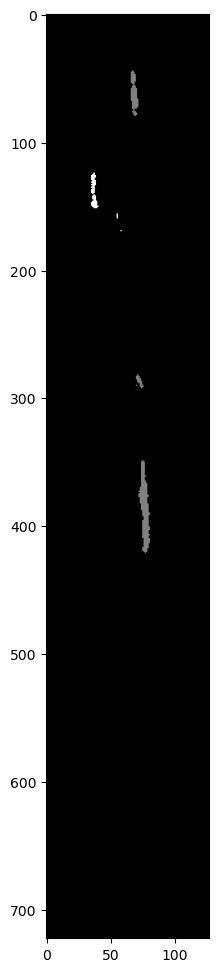

In [80]:
plt.figure(figsize=(12,12))
plt.imshow(testbin[:,:,500], 'gray', vmin=0, vmax=2)

In [81]:
ts=52
display = seg_data['segmented'].sel(timestep=ts, x=500)

Text(0.5, 1.0, 'timestep 52')

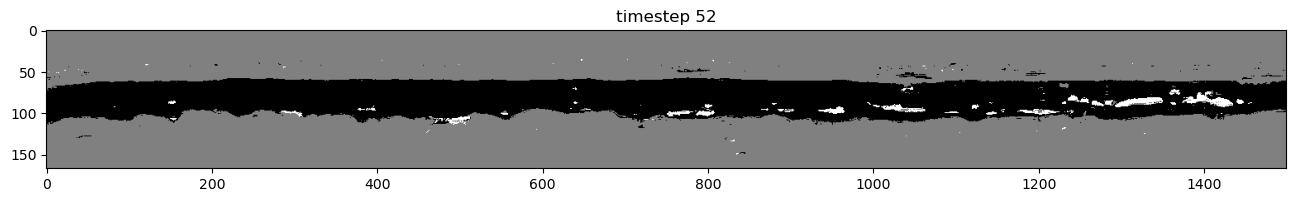

In [82]:
plt.figure(figsize=(16,9))
plt.imshow(display[:,160:1660], 'gray')
plt.title('timestep '+str(ts))

In [83]:
rawdisplay = reg_data[images[ts]][a:b,c:d,e:f].sel(x=500)

Text(0.5, 1.0, 'timestep 52')

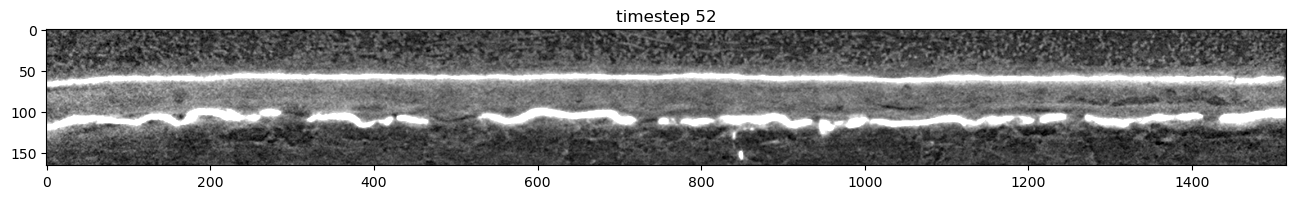

In [84]:
plt.figure(figsize=(16,9))
plt.imshow(rawdisplay[:1500], 'gray', vmin=10000, vmax=15000)
plt.title('timestep '+str(ts))

In [85]:
rawdisplay.shape

(166, 1516)

In [86]:
display[:,100:1600].shape

(167, 1500)

## try to find relations to echem

In [87]:
Atomo=0.1

(0.0, 1564285.85)

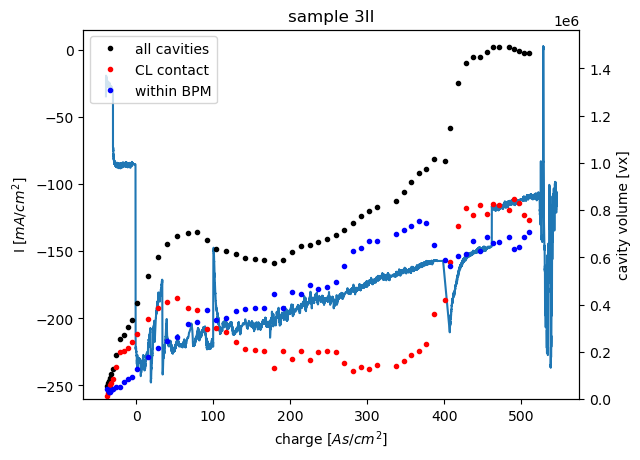

In [88]:
Qfun = sp.interpolate.interp1d(time, Q, fill_value=np.nan, bounds_error=False)
Efun = sp.interpolate.interp1d(time, E, fill_value=np.nan, bounds_error=False)
Ifun = sp.interpolate.interp1d(time, I/0.1, fill_value=np.nan, bounds_error=False)

Etomo = Efun(t_tomo)
Qtomo = Qfun(t_tomo)/1000   

#second calibration for after conditioning
# after 11.5 min, condtioning finished
ts_tomo_op = np.argmin(np.abs(t_tomo-11.5*60))
CLA = CLA-CLA_calib2 
CLA = CLA*100
Qtomo = Qtomo - Qfun(11.5*60)/1000   
Itomo = Ifun(t_tomo)

fig, ax  = plt.subplots()
ax2 = ax.twinx()
ax2.plot(Qtomo/0.1,cav_vol,'k.', label='all cavities')
ax2.plot(Qtomo/0.1,CL_cav, 'r.', label='CL contact')
ax2.plot(Qtomo/0.1,BPM_cav, 'b.', label='within BPM')
# ax.plot((t_utc_tomo-t0)/60, (mem_vol_clean/mem_vol_clean.max()), 'r.', label='swelling')

# ax2.plot((t_utc_tomo-t0)/60-11.5,CL_cav3, '--', label='at CL')
# ax2.plot((t_utc_tomo-t0)/60-11.5,BPM_cav3, '--', label='in BPM')


# ax2.plot((t_utc_tomo-t0)/60-11.5,CL_cav4, '-.', label='at CL')
# ax2.plot((t_utc_tomo-t0)/60-11.5,BPM_cav4, '-.', label='in BPM')

ax2.legend()


ax.plot((Q-Qfun(11.5*60))/1000/0.1, I/.1,  label='I')
# plt.ylim(0,1E-12)
# plt.yscale('log')
ax.set_xlabel('charge [$As/cm^2$]')
ax.set_ylabel('I [$mA/cm^2$]')
ax2.set_ylabel('cavity volume [vx]')
plt.title('sample '+sample)
# ax.set_xlim(0)
# ax.set_ylim(0)
ax2.set_ylim(0)

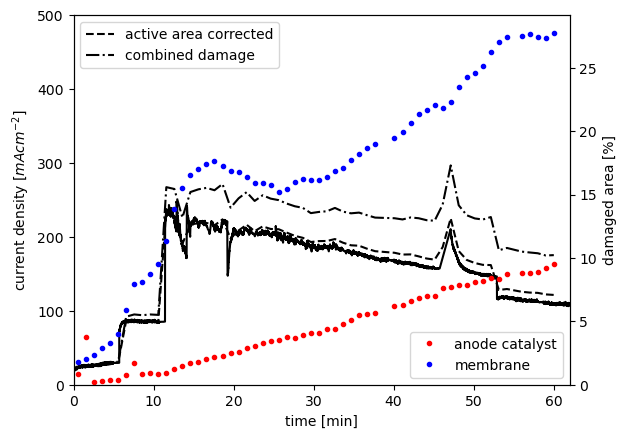

In [89]:
# mpl.rcParams["font.size"] = 10
fig, ax1 = plt.subplots()
ax2 = ax1.twinx()

test = xr.open_dataset(os.path.join(toppath, 'processing',  '06_anode_CL', '06_'+sample+'_anode_CL_segmented_filtered.nc'))
basearea = test['segmented'].shape[0]*test['segmented'].shape[2]
test.close()

CLarea_diff_scan = xr.load_dataset(os.path.join(toppath, 'processing',  '06_anode_CL', sample+'_CLarea_holes_1dadfb8.nc'))['CL_damaged_area'].data
CLA = CLarea_diff_scan
CLA = CLA/basearea

# t_tomo = charge_dict[sample]['t_utc_tomo'] - charge_dict[sample]['t0']
pxmm = 2.75E-3
# CLA = CLA*pxmm**2

tomo_0 = np.nanargmin(np.abs(t_tomo))

Ifun = sp.interpolate.interp1d(time, I/0.1, fill_value=np.nan, bounds_error=False)
Itomo = Ifun(t_tomo)
# CLA_calib = charge_dict[sample]['CLarea'].min()
CLA_calib = np.nanmean(CLA[tomo_0-1:tomo_0+4])
if sample == '3II': #manually calibrate because of two outliers
    CLA_calib = 0.75/pxmm**2
# print(tomo_0,CLA_calib)
CLA = CLA-CLA_calib

Qtomo = Qfun(t_tomo)/1000   

#second calibration for after conditioning
# after 11.5 min, condtioning finished
ts_tomo_op = np.argmin(np.abs(t_tomo-11.5*60))
CLA_calib2 = np.nanmean(CLA[ts_tomo_op-1:ts_tomo_op+2])
CLA = CLA-CLA_calib2 
CLA = CLA*100+1

MLA = delam_count/delam_area.shape[0]/delam_area.shape[1]
MLA_calib = np.nanmean(MLA[ts_tomo_op-1:ts_tomo_op+2])
# MLA = MLA-MLA_calib

pxmm = 2.75E-3
# CLA = CLA*pxmm**2

tomo_0 = np.nanargmin(np.abs(t_tomo))
# CLA_calib = charge_dict[sample]['CLarea'].min()
ax2.plot((t_utc_tomo-t0)/60, CLA,'r.', label= 'anode catalyst')
ax2.plot((t_utc_tomo-t0)/60, MLA*100,'b.', label= 'membrane')
Qtomo = Qfun(t_tomo)/1000   

#second calibration for after conditioning
# after 11.5 min, condtioning finished
ts_tomo_op = np.argmin(np.abs(t_tomo-11.5*60))
Qtomo = Qtomo - Qfun(11.5*60)/1000   
Qcalib = Q - Qfun(11.5*60)
timecalib = time-11.5*60
ax1.plot(time/60, -I/Atomo,'k')
# ax1.plot((t_utc_tomo-t0)/60, -Itomo*Atomo/(Atomo*(100-CLA)/100),'k--', label='active area corrected')
ax1.plot((t_utc_tomo-t0)/60, -Itomo*Atomo/(Atomo*(100-CLA)/100),'k--', label='active area corrected')
ax1.plot((t_utc_tomo-t0)/60, -Itomo*Atomo/(Atomo*(100-CLA-MLA*100)/100),'k-.', label='combined damage')
t_tomo_calib = t_tomo - 11.5*60
# ax2.plot((t_utc_tomo-t0)/60, CLarea_old*(2.75E-3)**2,'bo')
ax1.set_xlim(0,62)
# ax1.set_ylim(0,255)
# ax2.set_ylim(10.05,11.3)
ax1.set_xlabel('time [min]')
ax1.set_ylabel('current density [$mAcm^{-2}$]')
ax2.set_ylabel('damaged area [%]')
ax2.set_ylim(0)
ax1.set_ylim(0,500)
ax1.legend(loc = 'upper left')
ax2.legend(loc = 'lower right')

In [90]:
CLA_calib2

-99173.48551399393

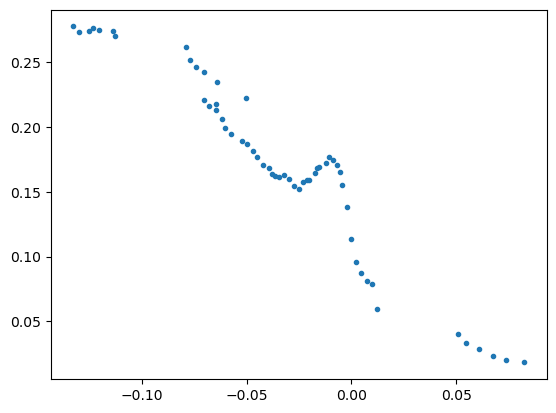

In [91]:
plt.plot(-Qtomo/Itomo/Etomo,MLA, '.')

In [92]:
# ax2.plot(Qtomo/0.1,cav_vol,'k.', label='all cavities')
# ax2.plot(Qtomo/0.1,CL_cav, 'r.', label='CL contact')
# ax2.plot(Qtomo/0.1,BPM_cav,

Text(0.5, 1.0, '3II')

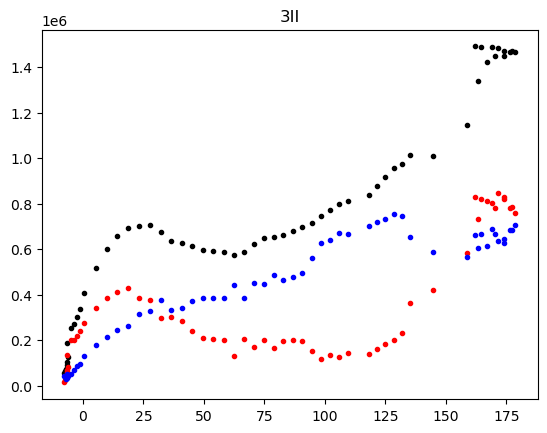

In [93]:
x = -Qtomo*Etomo
# x = np.log(-Itomo)/Etomo

plt.plot(x,cav_vol, 'k.')
plt.plot(x, CL_cav, 'r.')
plt.plot(x, BPM_cav, 'b.')

# plt.xlim(0.5,0.8)
# plt.xlim(-2,-1.3)
# plt.ylim(0,1.5E6)
plt.title(sample)

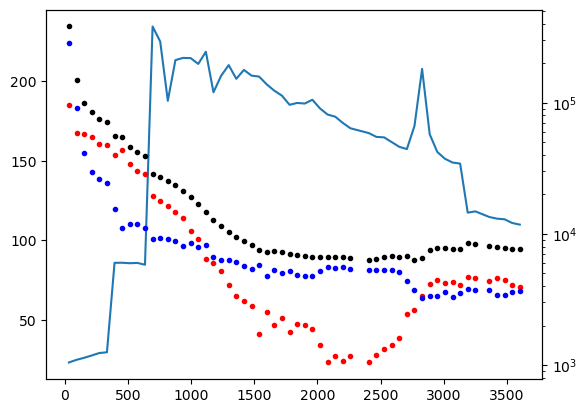

In [94]:
Qtomo2 = Qtomo+Qfun(11.5*60)/1000
x = Qtomo2
x = t_tomo
fig, ax = plt.subplots()

ax.plot(x, -Itomo)
ax2 = ax.twinx()
ax2.plot(x,-1/Etomo/Qtomo2*cav_vol,'k.')
ax2.plot(x,-1/Etomo/Qtomo2*CL_cav,'r.')
ax2.plot(x,-1/Etomo/Qtomo2*BPM_cav,'b.')



# plt.xscale('log')
ax2.set_yscale('log')
# ax2.set_ylim(0,50000)

(-5e-10, 1e-09)

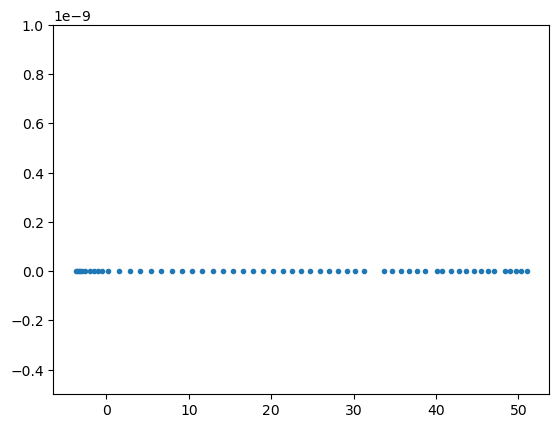

In [95]:
Vtomo = cav_vol*px**3
p = -np.gradient(Vtomo, Qtomo*Etomo*Itomo*Atomo/(Atomo*(100-CLA-MLA*100)/100))
plt.plot(Qtomo,p,'.')
# plt.yscale('log')
plt.ylim(-0.5E-9,1E-9)

In [96]:
1/100E5

1e-07

(0.0, 10000.0)

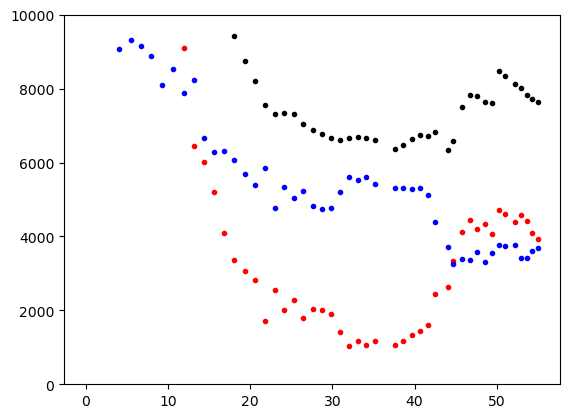

In [97]:
Qtomo2 = Qtomo+Qfun(11.5*60)/1000

# plt.plot(Qtomo2,-Etomo*Qtomo2/cav_vol,'k.')
# plt.plot(Qtomo2,-Etomo*Qtomo2/CL_cav,'r.')
# plt.plot(Qtomo2,-Etomo*Qtomo2/BPM_cav,'b.')

# plt.xscale('log')
# plt.yscale('log')

plt.plot(Qtomo2,-1/(Etomo*Qtomo2/cav_vol),'k.')
plt.plot(Qtomo2,-1/(Etomo*Qtomo2/CL_cav),'r.')
plt.plot(Qtomo2,-1/(Etomo*Qtomo2/BPM_cav),'b.')

# plt.xscale('log')
# plt.yscale('log')
plt.ylim(0,10000)

In [98]:
test = results[20][0]

In [99]:
testbin = test.copy()

### gas volume vs charge

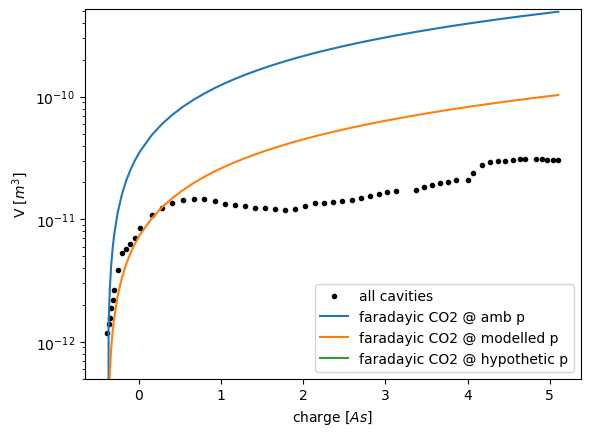

In [100]:
N_A = 6.0221415E23 # mol-1 Avogadro constant
R = 8.314472# gas constant m3⋅Pa⋅K−1⋅mol−1
T = 273+45 #K, temperature 45°C
e = 1.602176634E-19 #C C[1]
f = 1/3
f = f*10E-4
vx = px**3
p = 101325 # Pa, ambient pressure
pmod = 485E3 # Pa, modeled pressure
phyp = 7E8 #Pa, hypothetic pressure if all CO2 stays in membrane

plt.plot(Qtomo*0.1,cav_vol*vx,'k.', label='all cavities')
plt.plot(Qtomo*0.1, (Qtomo-np.nanmin(Qtomo))*0.1*f*R*T/e/N_A/p, label='faradayic CO2 @ amb p')
plt.plot(Qtomo*0.1, (Qtomo-np.nanmin(Qtomo))*0.1*f*R*T/e/N_A/pmod, label='faradayic CO2 @ modelled p')
plt.plot(Qtomo*0.1, (Qtomo-np.nanmin(Qtomo))*0.1*f*R*T/e/N_A/phyp, label='faradayic CO2 @ hypothetic p')

plt.ylabel('V [$m^3$]')
plt.xlabel('charge [$As$]')
plt.ylim(5E-13)
plt.legend()
plt.yscale('log')

NameError: name 'CLgas_I' is not defined

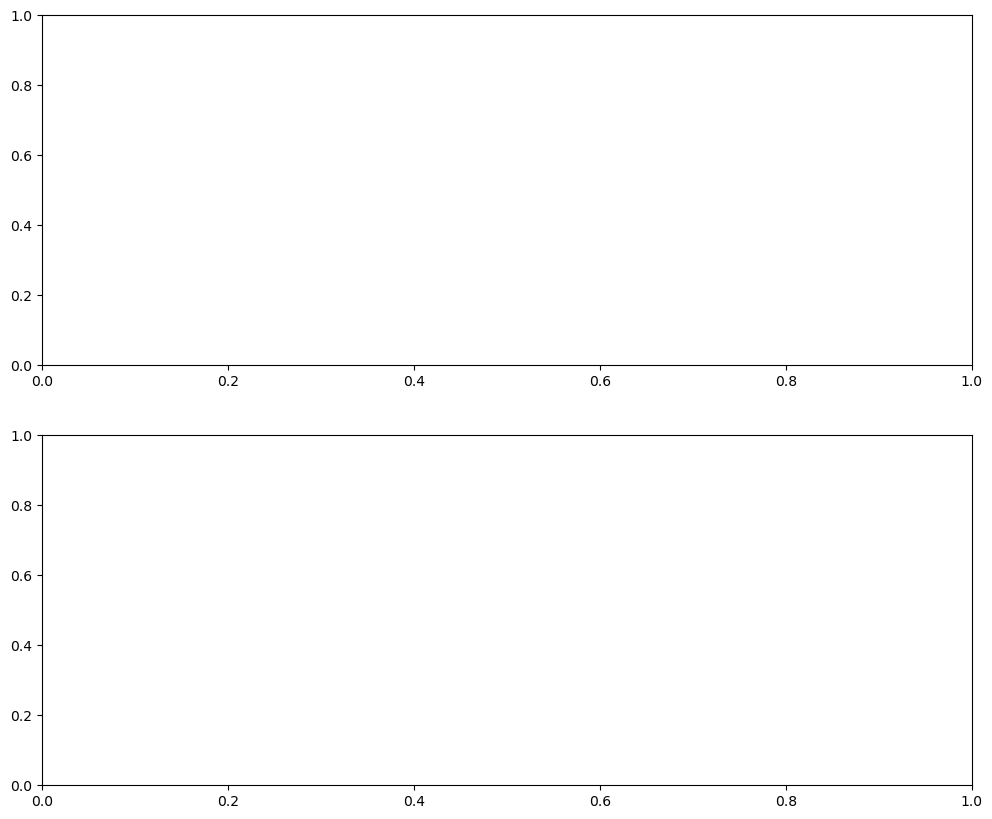

In [101]:
fig, axs = plt.subplots(2,1,figsize=(12,10))
axs[0].imshow(-CLgas_I,vmin = 30, vmax=220)
# plt.colorbar(label='I [$mA/cm^2$]')
axs[1].imshow(-BPM_I,vmin = 30, vmax=220)
# plt.colorbar(label='I [$mA/cm^2$]')
# plt.title('CL gas')

### Damaged area separated for CL and BPM

In [102]:
def area_per_position(result):
    label, label_ids, label_counts, CL_label_ids, totcav, CLcav, BPMcav = result
    test = np.zeros(label.shape, dtype=np.uint8)
    for i in label_ids[1:]:
        if i in CL_label_ids:
            col = 2
        else:
            col = 1
        test[np.where(label==i)] = col
        
    return test

In [103]:
shp4D = testbin.shape+cav_vol.shape
label_2 = np.zeros(shp4D, dtype=np.uint8)

for ts in range(shp4D[-1]):
    label_2[...,ts] = area_per_position(results[ts])

In [108]:
CL_gas_area = (label_2==2).any(axis=1).sum(axis=(0,1))
BPM_gas_area = (label_2==1).any(axis=1).sum(axis=(0,1))


In [109]:
overlap_area = label_2.any(axis=1).sum(axis=(0,1))

Text(0, 0.5, 'I [$mA/cm^2$]')

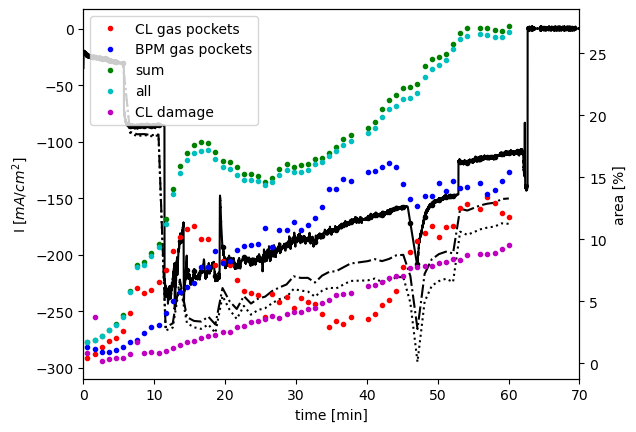

In [110]:
fig, ax = plt.subplots()

ax2 = ax.twinx()
refarea = label_2.shape[0]*label_2.shape[2]
ax2.plot(t_tomo/60, CL_gas_area/refarea*100, 'r.', label = 'CL gas pockets')
ax2.plot(t_tomo/60, BPM_gas_area/refarea*100,'b.', label = 'BPM gas pockets')
ax2.plot(t_tomo/60, BPM_gas_area/refarea*100+CL_gas_area/refarea*100,'g.', label = 'sum')
ax2.plot(t_tomo/60, overlap_area/refarea*100 ,'c.', label = 'all')
ax2.plot(t_tomo/60, CLA ,'m.', label = 'CL damage')

MLA2 = overlap_area/refarea*100

ax.plot(time/60, I/Atomo,'k')
ax.plot(t_tomo/60, Itomo,'k.')
# ax.plot((t_utc_tomo-t0)/60, -Itomo*Atomo/(Atomo*(100-CLA)/100),'k--', label='active area corrected')
ax.plot(t_tomo/60, Itomo*Atomo/(Atomo*(100-MLA2)/100),'k-.', label='BPM active area corrected')
ax.plot(t_tomo/60, Itomo*Atomo/(Atomo*(100-MLA2-CLA)/100),'k:', label='combined damage')



# ax.plot(time/60, -E,'k')

ax2.set_ylabel('area [%]')
ax.set_xlabel('time [min]')
ax.set_xlim(0,70)
# ax.set_ylim(-260,80)
ax2.legend()
ax.set_ylabel('I [$mA/cm^2$]')

NameError: name 'cm' is not defined

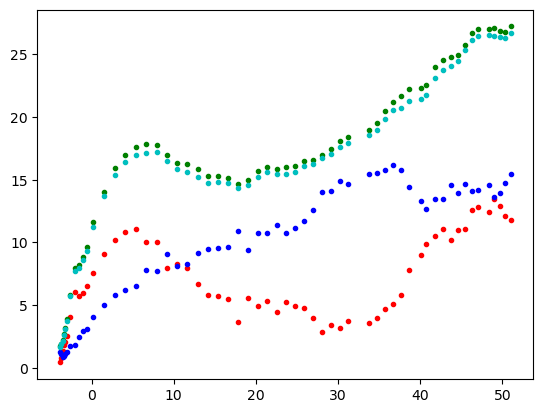

In [111]:
fig, ax = plt.subplots()

refarea = label_2.shape[0]*label_2.shape[2]

x = Qtomo

ax.plot(x, CL_gas_area/refarea*100, 'r.', label = 'CL gas pockets')
ax.plot(x, BPM_gas_area/refarea*100,'b.', label = 'BPM gas pockets')
ax.plot(x, BPM_gas_area/refarea*100+CL_gas_area/refarea*100,'g.', label = 'sum')
ax.plot(x, overlap_area/refarea*100 ,'c.', label = 'all')
# ax.plot(x, CLA ,'m.', label = 'CL damage')
ax.scatter(x, CLA, c=-Itomo, cmap = cm.inferno, vmin=50, vmax=250, s=6, label = 'CL damage')
ax.set_ylabel('area [%]')
# ax.set_xlabel('I [$mA/cm^2$]')
ax.legend()
# ax.set_xlim(-200,0)
# ax.set_xscale('log')
# ax.set_yscale('log')
# ax.set_xlim(0,0.0025)

(0.0, 5.0)

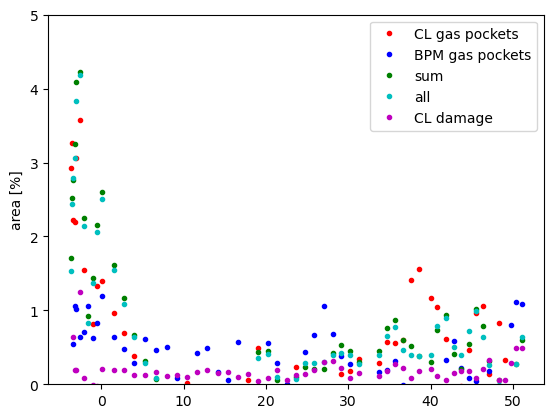

In [112]:
fig, ax = plt.subplots()

refarea = label_2.shape[0]*label_2.shape[2]

x = Qtomo

def funy(y):
    y = np.gradient(y,Qtomo)
    return y

ax.plot(x, funy(CL_gas_area/refarea*100), 'r.', label = 'CL gas pockets')
ax.plot(x, funy(BPM_gas_area/refarea*100),'b.', label = 'BPM gas pockets')
ax.plot(x, funy(BPM_gas_area/refarea*100+CL_gas_area/refarea*100),'g.', label = 'sum')
ax.plot(x, funy(overlap_area/refarea*100) ,'c.', label = 'all')
ax.plot(x, funy(CLA) ,'m.', label = 'CL damage')
# ax.scatter(x, np.gradient(CLA), c=-Itomo, cmap = cm.plasma, vmin=25, vmax=200, s=6, label = 'CL damage')
ax.set_ylabel('area [%]')
# ax.set_xlabel('I [$mA/cm^2$]')
ax.legend()
ax.set_ylim(0,5)
# ax.set_xscale('log')
# ax.set_yscale('log')
# ax.set_xlim(0,0.1)

In [113]:
from matplotlib import cm

### overlap gas and CL damage

In [114]:
# CLarea_diff_scan = xr.load_dataset(os.path.join(toppath, 'processing',  '06_anode_CL', sample+'_CLarea_holes_1dadfb8.nc'))#['CL_damaged_area'].data
CLarea_diff_scan = xr.open_dataset(os.path.join(toppath, 'processing',  '06_anode_CL', sample+'_CLarea_holes_with_area_5306713.nc'))#['CL_damaged_area'].data


In [115]:
CLarea_diff_scan['CL_damaged_area'].shape

(764, 2016, 63)

In [116]:
label_2.shape

(723, 127, 1350, 63)

In [117]:
ts = 60

test = CLarea_diff_scan['CL_damaged_area'][ar:br,er+250:er+1600,ts][20:-20,...].data>0

# test2 = label_2[...,ts].any(axis=1)
test21 = (label_2[...,ts]==1).any(axis=1)
test22 = (label_2[...,ts]==2).any(axis=1)

im_test = test21*1+test22*3+test*5
mask = im_test==0
# im_test = im_test*1.0
# im_test[mask] = np.nan
im_test[im_test>2] = im_test[im_test>1]-1
im_test[im_test>6] = im_test[im_test>6]-1

im_test = im_test*1.0
im_test[mask] = np.nan

In [118]:
color_annot = ['BPM gas', 'CL gas', 'BPM+CL gas', 'CL hole', 'BPM gas + CL hole', 'CL gas + CL hole', 'all', 'n.a.', 'n.a.', 'n.a.']
color_annot_hist = ['BPM gas', 'CL gas', 'BPM+CL gas', 'CL hole', 'BPM gas + CL hole', 'CL gas + CL hole', 'all']

In [119]:
np.nanmin(im_test)

1.0

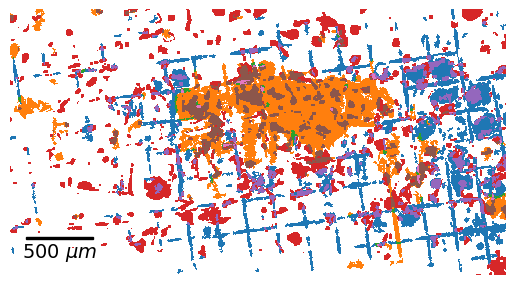

In [120]:
# fig, ax = plt.subplots(figsize=(16,9))
# cax = ax.imshow(im_test, 'tab10', vmin=1, vmax=10)
# cbar = fig.colorbar(cax)
# cbar.ax.set_yticklabels(color_annot)

fig, ax = plt.subplots()
cax = ax.imshow(im_test, 'tab10', vmin=1, vmax=10, interpolation='none')

ax.axis('off')
scalebar = AnchoredSizeBar(ax.transData,
                           500/2.75, '500 $\mu m$', 'lower left', 
                           pad=0.5,
                           color='black',
                           frameon=False,
                           size_vertical=5,
                           fontproperties=fontprops)
ax.add_artist(scalebar)
# cbar = fig.colorbar(cax)
# cbar.ax.set_yticklabels(color_annot)

In [121]:
def create_histogram(im_test):
    colors, color_counts = np.unique(im_test, return_counts=True)
    colors = colors[1:]
    color_counts = color_counts[1:]
    
    refcolors = [1,2,3,4,5,7,8]
    refcounts = []
    
    for col in refcolors:
        if col in colors:
            count = color_counts[np.argwhere(colors==col)][0][0]
        else:
            count = 0
        refcounts.append(count)
        
    return refcolors, refcounts
    

In [122]:
proj_shp = (label_2.shape[0], label_2.shape[2], label_2.shape[3])

projections = np.zeros(proj_shp, dtype=np.uint8)
histograms = np.zeros((7,label_2.shape[3]))

for ts in range(label_2.shape[-1]):
    if ts%5==0: print(ts)
    test = CLarea_diff_scan['CL_damaged_area'][ar:br,er+250:er+1600,ts][20:-20,...].data==3
    test = skimage.morphology.binary_dilation(test)

    # test2 = label_2[...,ts].any(axis=1)
    test21 = (label_2[...,ts]==1).any(axis=1)
    test22 = (label_2[...,ts]==2).any(axis=1)

    im_test = test21*1+test22*3+test*5
    mask = im_test==0
    # im_test = im_test*1.0
    # im_test[mask] = np.nan
    im_test[im_test>2] = im_test[im_test>1]-1
    # im_test = np.uint8(im_test)
    
    refcolors, refcounts = create_histogram(im_test)
    im_test[im_test>6] = im_test[im_test>6]-1
    projections[...,ts] = im_test
    histograms[:,ts] = refcounts
    
    continue
    
    im_test = im_test*1.0
    im_test[mask] = np.nan
    
#     plt.figure()
#     plt.imshow(im_test, 'tab10', vmin=1, vmax=10, interpolation='none')
#     impath = os.path.join(toppath, 'plots', 'test_videos', sample+'_different_areas', f'{ts:02d}'+'.png')

#     # imageio.imsave(impath, im_test)
#     plt.savefig(impath)
    
    fig, ax = plt.subplots()
    ax.imshow(im_test, 'tab10', vmin=1, vmax=10, interpolation='none')

    ax.axis('off')
    scalebar = AnchoredSizeBar(ax.transData,
                               500/2.75, '500 $\mu m$', 'lower left', 
                               pad=0.5,
                               color='black',
                               frameon=False,
                               size_vertical=5,
                               fontproperties=fontprops)
    ax.add_artist(scalebar)
    impath = os.path.join(toppath, 'plots', 'test_videos', sample+'_different_areas', f'{ts:02d}'+'.png')
    plt.savefig(impath, bbox_inches='tight', dpi=300)
    plt.close()
    
    
    
    plt.figure()
    plt.bar(color_annot_hist, refcounts)
    plt.xticks(rotation=90)
    plt.ylabel('area [px]')
    plt.ylim(0,1.2E5)
    plt.savefig(os.path.join(toppath, 'plots', 'test_videos', sample+'_different_areas_hist', f'{ts:02d}'+'.png'), bbox_inches='tight')
    plt.close()
    

0
5
10
15
20
25
30
35
40
45
50
55
60


In [123]:
len(refcolors)

7

Text(0, 0.5, 'area [px]')

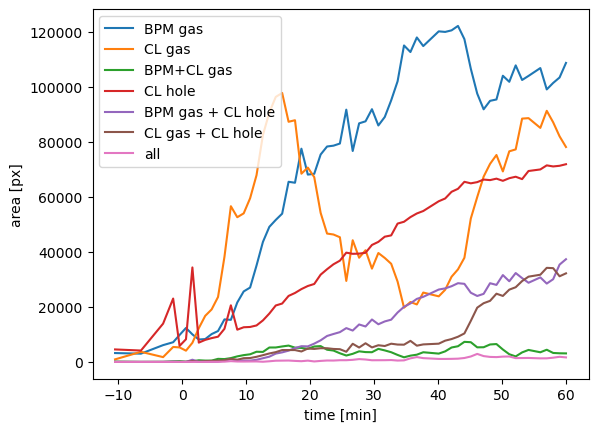

In [124]:
for i in range(histograms.shape[0]):
    plt.plot(t_tomo/60,histograms[i,:], label = color_annot[i])
plt.legend()
plt.xlabel('time [min]')
plt.ylabel('area [px]')

### projection along time

In [125]:
CLgas_anytime = (label_2==2).any(axis=(1,3))

In [126]:
BPMgas_anytime = (label_2==1).any(axis=(1,3))

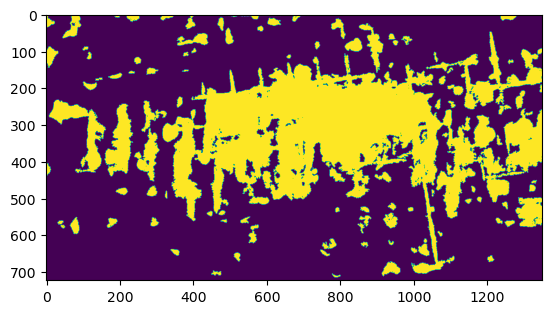

In [127]:
plt.imshow(CLgas_anytime)

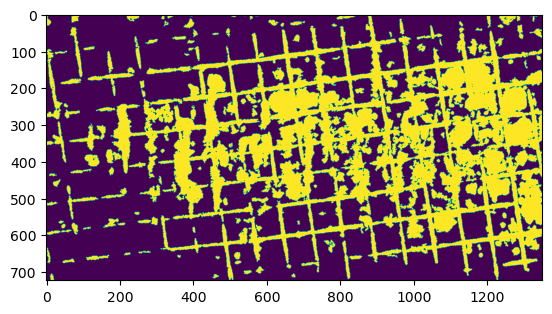

In [128]:
plt.imshow(BPMgas_anytime)

In [129]:
CLhole_anytime = (CLarea_diff_scan['CL_damaged_area'][ar:br,er+250:er+1600,:][20:-20,...].data==3).any(axis=-1)

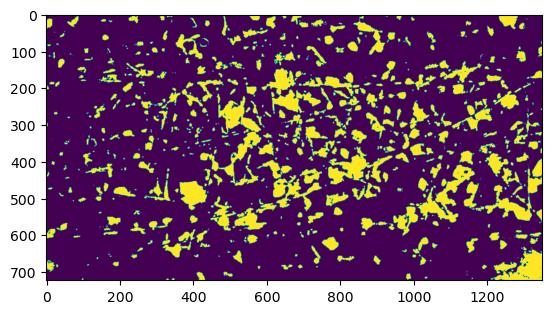

In [130]:
plt.imshow(CLhole_anytime)

/tmp/ipykernel_21562/3272403597.py:27: UserWarning: FixedFormatter should only be used together with FixedLocator
  cbar.ax.set_yticklabels(color_annot)


[Text(1, 1.0, 'BPM gas'),
 Text(1, 2.0, 'CL gas'),
 Text(1, 3.0, 'BPM+CL gas'),
 Text(1, 4.0, 'CL hole'),
 Text(1, 5.0, 'BPM gas + CL hole'),
 Text(1, 6.0, 'CL gas + CL hole'),
 Text(1, 7.0, 'all'),
 Text(1, 8.0, 'n.a.'),
 Text(1, 9.0, 'n.a.'),
 Text(1, 10.0, 'n.a.')]

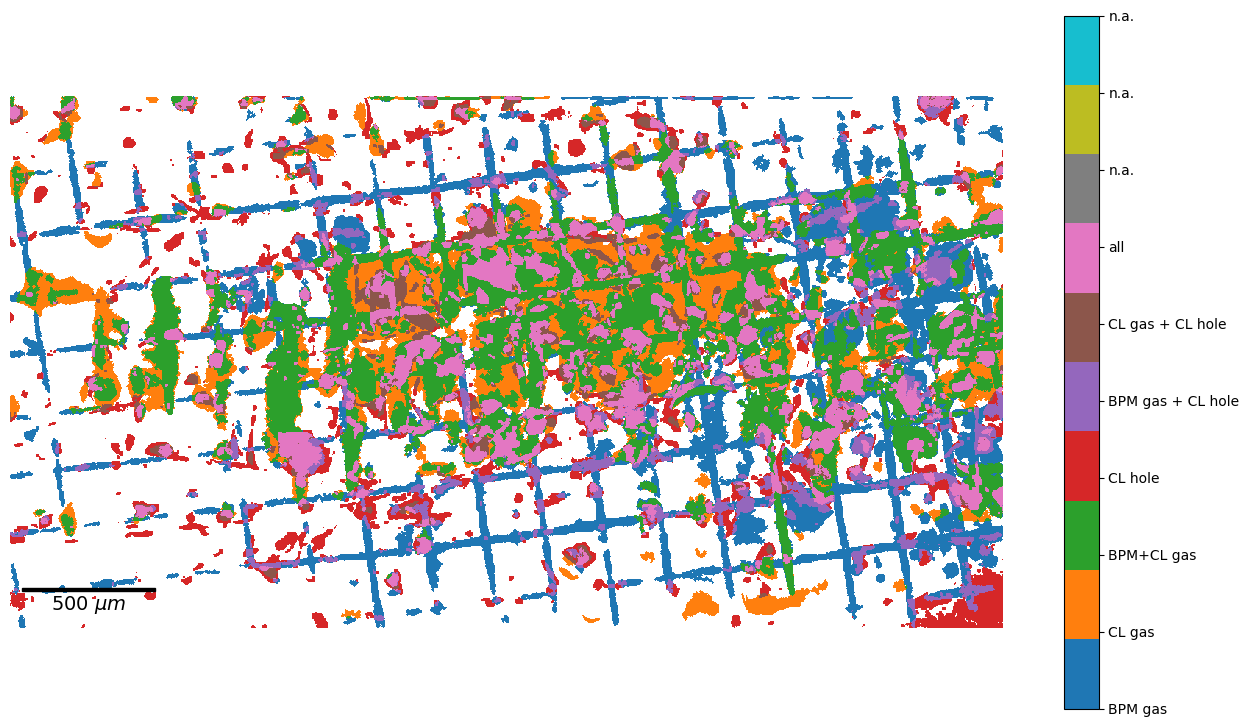

In [131]:
# plt.imshow(CLhole_anytime*1+CLgas_anytime*2, 'tab10', interpolation='none',vmin=0,vmax=9)
# plt.colorbar(yticklabels=['no gas', 'CL hole', 'CL gas', 'CL hole+gas'])


anytime = BPMgas_anytime*1+CLgas_anytime*3+CLhole_anytime*5
mask = anytime ==0
anytime[anytime>2] = anytime[anytime>1]-1
anytime[anytime>6] = anytime[anytime>6]-1

anytime = anytime*1.0
anytime[mask] = np.nan


fig, ax = plt.subplots(figsize=(16,9))
cax = ax.imshow(anytime, 'tab10', interpolation='none',vmin=1,vmax=10)

ax.axis('off')
scalebar = AnchoredSizeBar(ax.transData,
                           500/2.75, '500 $\mu m$', 'lower left', 
                           pad=0.5,
                           color='black',
                           frameon=False,
                           size_vertical=5,
                           fontproperties=fontprops)
ax.add_artist(scalebar)
cbar = fig.colorbar(cax)
cbar.ax.set_yticklabels(color_annot)

### label gas holes with timestep

In [132]:
def convert_ts_to_time(im_ts):
    shp = im_ts.shape
    im_time = np.zeros(shp)
    
    for x in range(shp[0]):
        for y in range(shp[1]):
            ts = im_ts[x,y]
            if np.isfinite(ts):
                t_xy = t_tomo[int(ts)]
            else:
                t_xy = np.nan
            im_time[x,y] = t_xy
    return im_time

In [133]:
BPM_first = np.argmax((label_2==1).any(axis=(1)), axis=-1)

In [134]:
mask = BPM_first==0
BPM_first=BPM_first*1.0
BPM_first[mask] = np.nan

Text(0.5, 1.0, 'BPM gas')

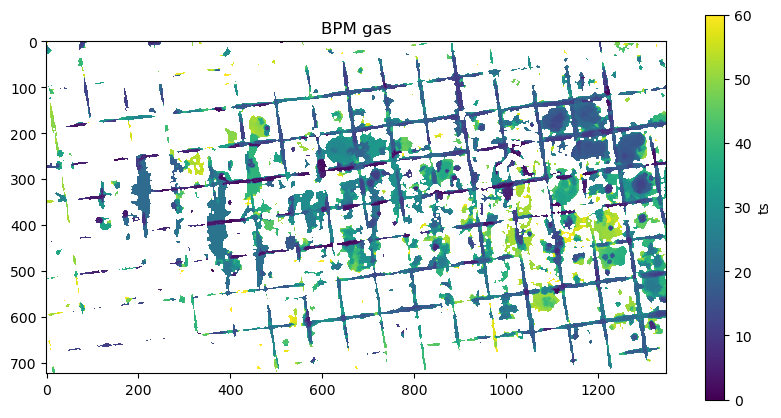

In [135]:
plt.figure(figsize=(10,5))
plt.imshow(BPM_first,vmin=0, vmax=60)
plt.colorbar(label='ts')
plt.title('BPM gas')

In [136]:
BPM_time = convert_ts_to_time(BPM_first)
BPM_I = Ifun(BPM_time)

Text(0.5, 1.0, 'BPM gas')

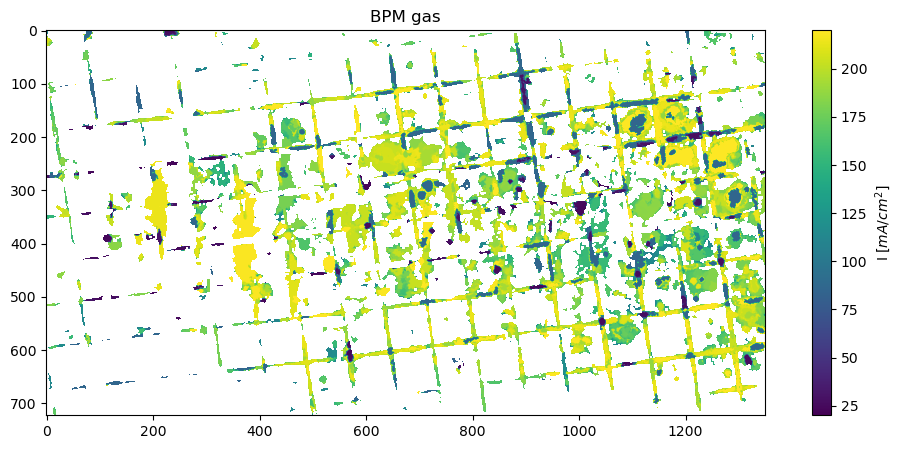

In [137]:
plt.figure(figsize=(12,5))
plt.imshow(-BPM_I,vmin = 20, vmax=220)
plt.colorbar(label='I [$mA/cm^2$]')
plt.title('BPM gas')

In [138]:
BPM_Q = Qfun(BPM_time)

Text(0.5, 1.0, 'BPM gas')

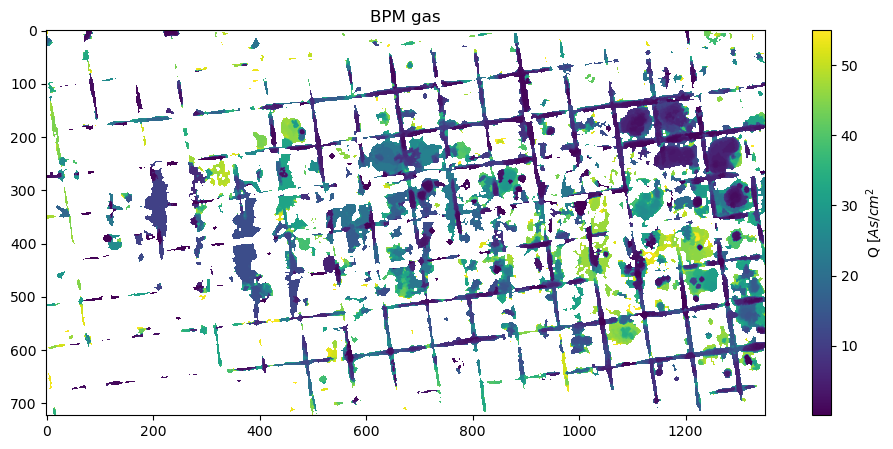

In [139]:
plt.figure(figsize=(12,5))
plt.imshow(BPM_Q/1000)
plt.colorbar(label='Q [$As/cm^2$')
plt.title('BPM gas')

In [140]:
CLgas_first = np.argmax((label_2==2).any(axis=(1)), axis=-1)

In [141]:
mask = CLgas_first==0
CLgas_first=CLgas_first*1.0
CLgas_first[mask] = np.nan

Text(0.5, 1.0, 'CL gas')

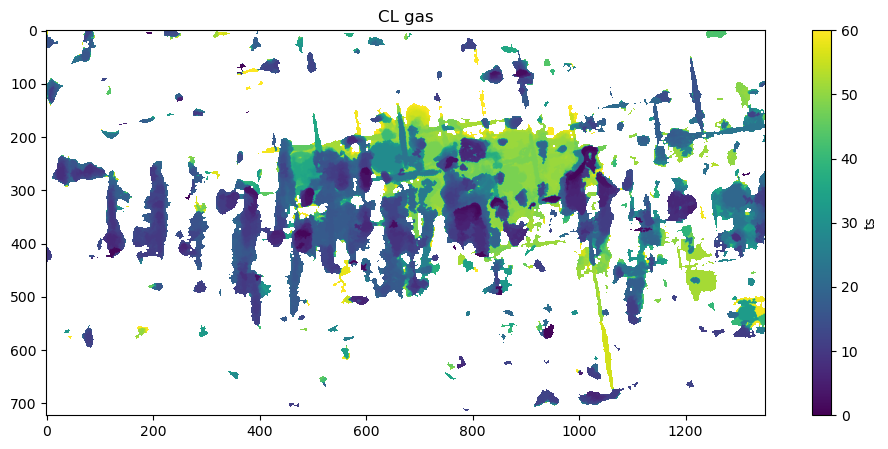

In [142]:
plt.figure(figsize=(12,5))
plt.imshow(CLgas_first,vmin=0, vmax=60)
plt.colorbar(label = 'ts')
plt.title('CL gas')

In [143]:
CLgas_time = convert_ts_to_time(CLgas_first)
CLgas_I = Ifun(CLgas_time)

Text(0.5, 1.0, 'CL gas')

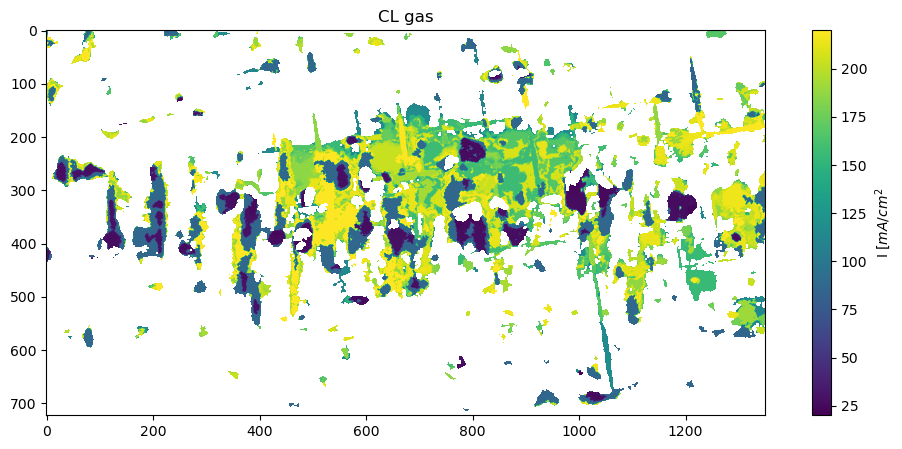

In [144]:
plt.figure(figsize=(12,5))
plt.imshow(-CLgas_I,vmin = 20, vmax=220)
plt.colorbar(label='I [$mA/cm^2$')
plt.title('CL gas')

In [145]:
def get_bounds(vmin, vmax):
    step = (vmax-vmin)/6
    bounds = np.arange(vmin, vmax+1E-9, step)
    return bounds

In [146]:
import matplotlib as mpl

In [147]:
cmap = mpl.cm.viridis
bounds = get_bounds(50, 200)
norm = mpl.colors.BoundaryNorm(bounds, cmap.N, extend='both')

fig.colorbar(mpl.cm.ScalarMappable(norm=norm, cmap=cmap),
             cax=ax, orientation='horizontal',
             label="Discrete intervals with extend='both' keyword")

In [148]:
CLgas_Q = Qfun(CLgas_time)

Text(0.5, 1.0, 'CL gas')

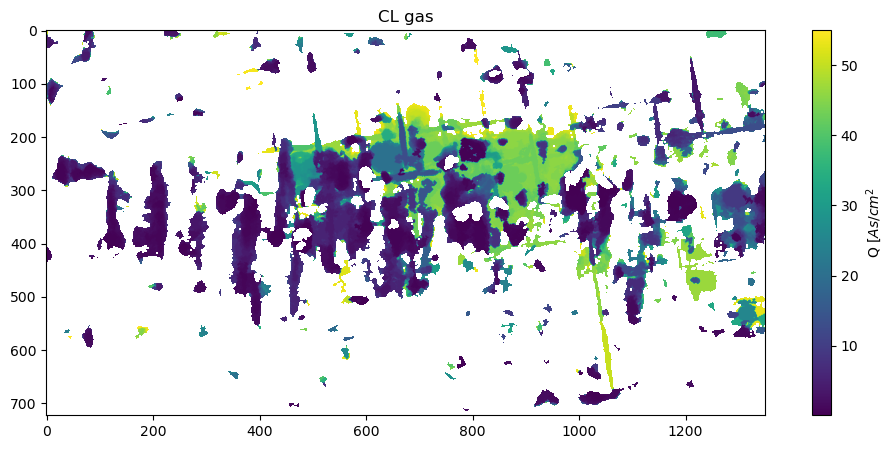

In [149]:
plt.figure(figsize=(12,5))
plt.imshow(CLgas_Q/1000)
plt.colorbar(label='Q [$As/cm^2$')
plt.title('CL gas')

/tmp/ipykernel_21562/1498840265.py:1: RuntimeWarning: All-NaN slice encountered
  Gas = np.nanmin(np.dstack([CLgas_first,BPM_first]),axis=-1)


Text(0.5, 1.0, 'any gas')

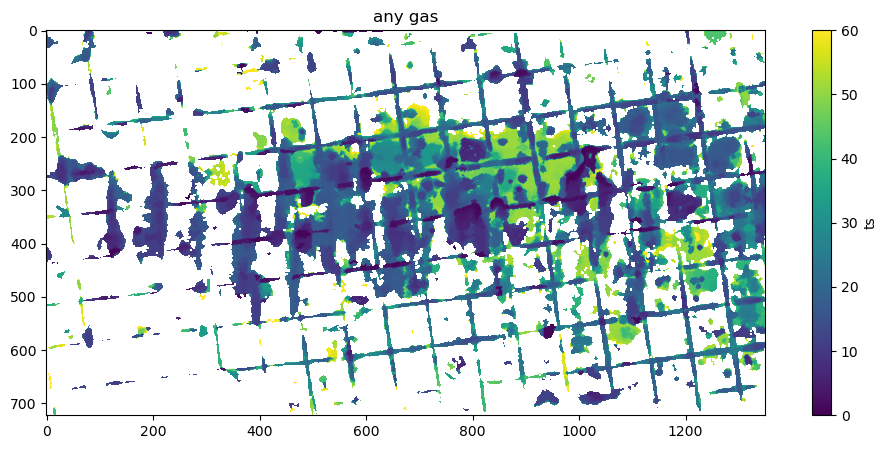

In [150]:
Gas = np.nanmin(np.dstack([CLgas_first,BPM_first]),axis=-1)
plt.figure(figsize=(12,5))
plt.imshow(Gas,vmin=0, vmax=60)
plt.colorbar(label = 'ts')
plt.title('any gas')

In [151]:
Gas_time = convert_ts_to_time(Gas)
Gas_I = Ifun(Gas_time)

Text(0.5, 1.0, 'any gas')

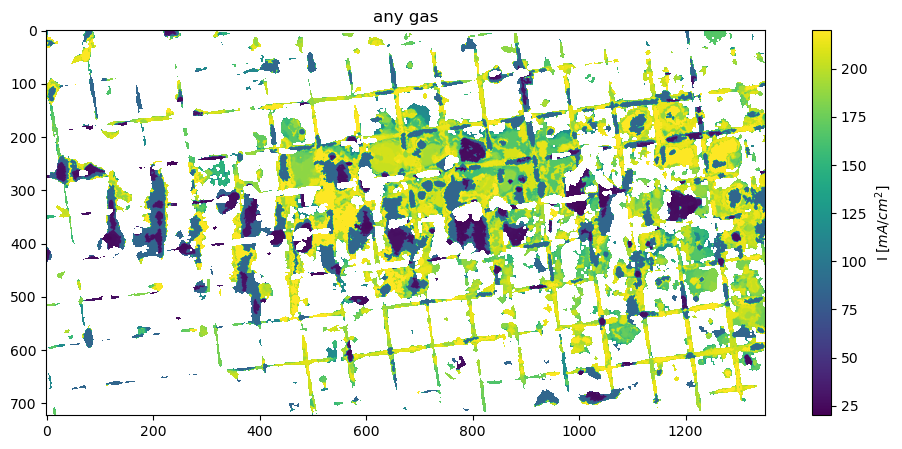

In [152]:
plt.figure(figsize=(12,5))
plt.imshow(-Gas_I,vmin = 20, vmax=220)
plt.colorbar(label='I [$mA/cm^2$]')
plt.title('any gas')

In [153]:
Gas_Q = Qfun(Gas_time)

Text(0.5, 1.0, 'any gas')

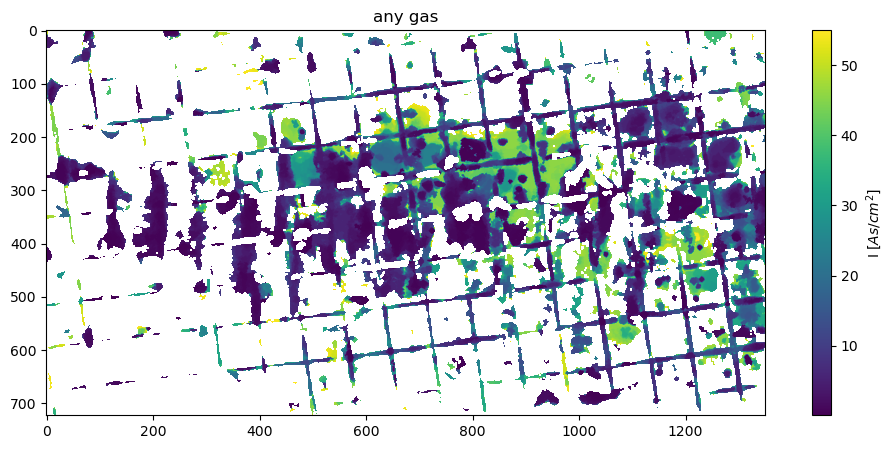

In [154]:
plt.figure(figsize=(12,5))
plt.imshow(Gas_Q/1000)
plt.colorbar(label='I [$As/cm^2$]')
plt.title('any gas')

In [155]:
CLhole_first = np.argmax(CLarea_diff_scan['CL_damaged_area'][ar:br,er+250:er+1600,:][20:-20,...].data==3, axis=-1)

In [156]:
mask = CLhole_first==0
CLhole_first=CLhole_first*1.0
CLhole_first[mask] = np.nan

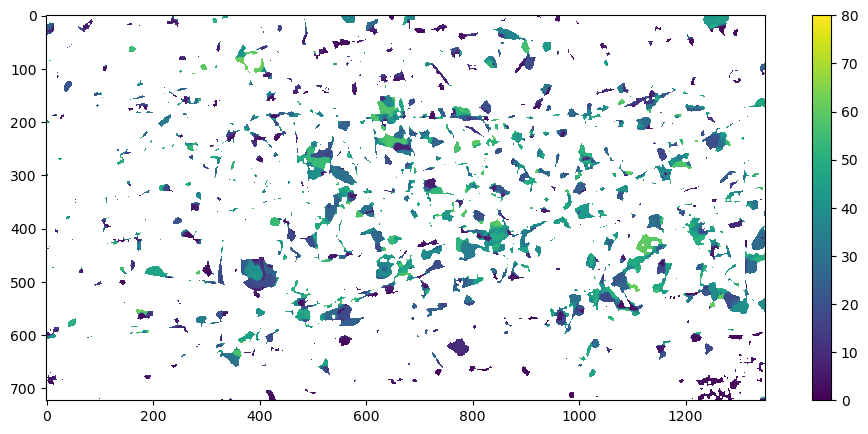

In [157]:
plt.figure(figsize=(12,5))
plt.imshow(CLhole_first,vmin=0, vmax=80)
plt.colorbar()

In [158]:
CLhole_time = convert_ts_to_time(CLhole_first)

Text(0.5, 1.0, 'CL holes')

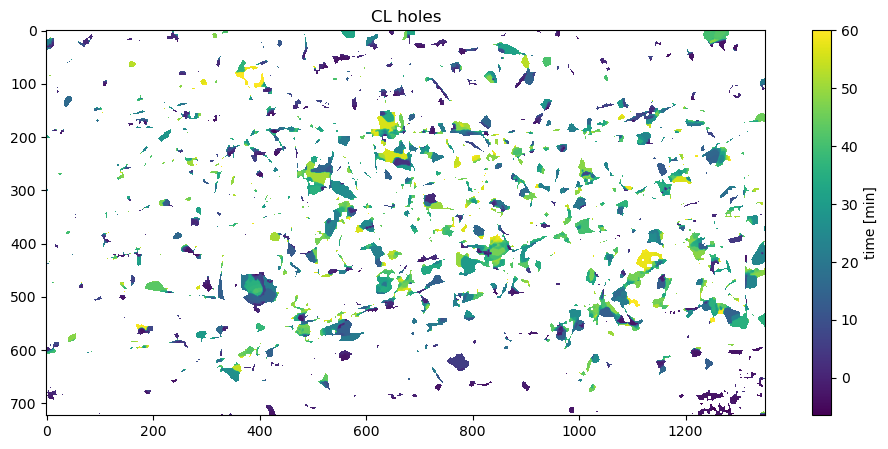

In [159]:
plt.figure(figsize=(12,5))
plt.imshow(CLhole_time/60)
plt.colorbar(label='time [min]')
plt.title('CL holes')

In [160]:
CLhole_I = Ifun(CLhole_time)

Text(0.5, 1.0, 'CL holes')

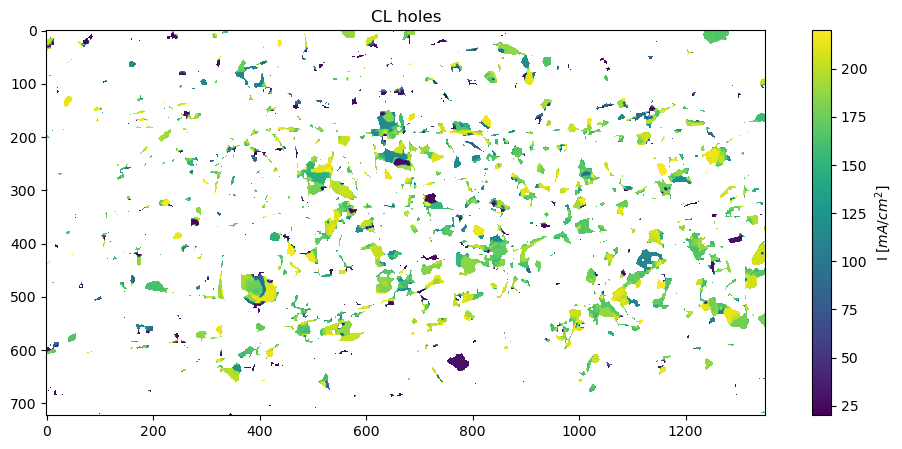

In [161]:
plt.figure(figsize=(12,5))
plt.imshow(-CLhole_I,vmin = 20, vmax=220)
plt.colorbar(label='I [$mA/cm^2$]')
plt.title('CL holes')

Text(0.5, 1.0, 'CL holes')

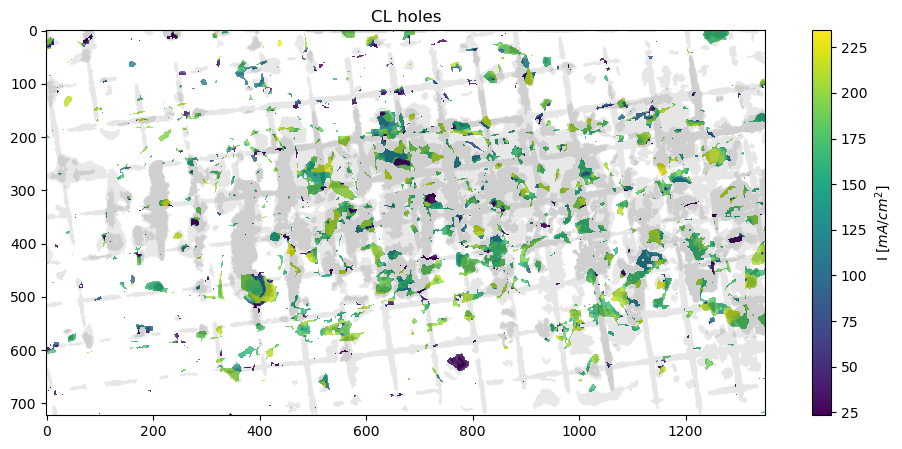

In [162]:
plt.figure(figsize=(12,5))
plt.imshow(-CLhole_I)
plt.colorbar(label='I [$mA/cm^2$]')
plt.imshow(CLgas_anytime,'binary', alpha = 0.1)
plt.imshow(BPMgas_anytime,'binary', alpha = 0.1)
plt.title('CL holes')

In [163]:
CLhole_Q = Qfun(CLhole_time)

Text(0.5, 1.0, 'CL holes')

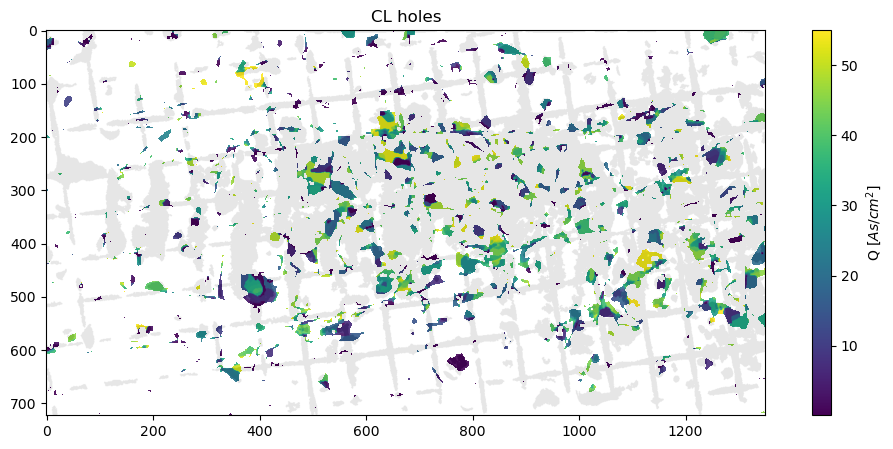

In [164]:
plt.figure(figsize=(12,5))
plt.imshow(CLhole_Q/1000)
plt.colorbar(label='Q [$As/cm^2$]')
plt.imshow(BPMgas_anytime+CLgas_anytime,'binary', alpha=0.1)
plt.title('CL holes')

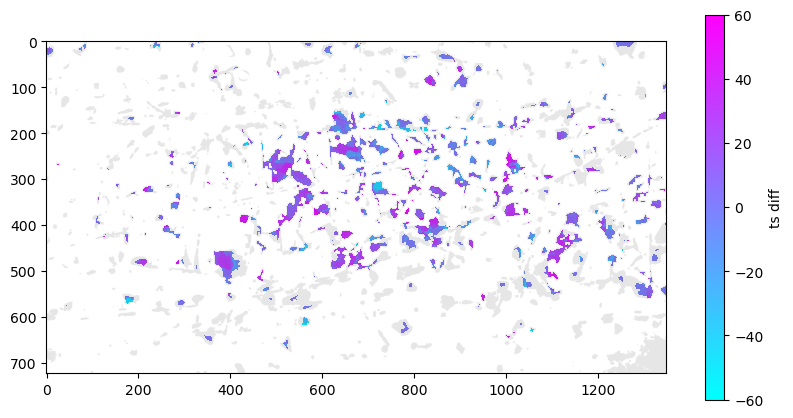

In [165]:
# overlap_mask = np.bitwise_and(CLhole_first>0, CLgas_first>0)

plt.figure(figsize=(10,5))
plt.imshow((CLhole_first-CLgas_first),'cool',vmin=-60, vmax=60)
plt.colorbar(label='ts diff')
plt.imshow(CLhole_anytime,'binary', alpha=0.1)


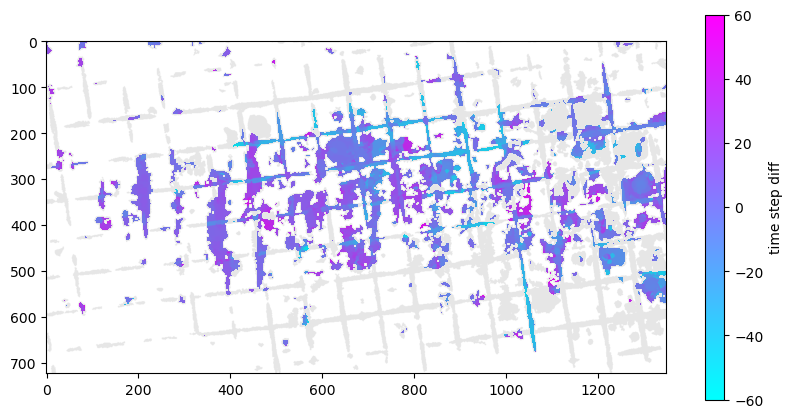

In [166]:
# overlap_mask = np.bitwise_and(CLhole_first>0, CLgas_first>0)

plt.figure(figsize=(10,5))
plt.imshow((-CLgas_first+BPM_first),'cool',vmin=-60, vmax=60)
plt.colorbar(label='time step diff')
plt.imshow(BPMgas_anytime,'binary', alpha=0.1)


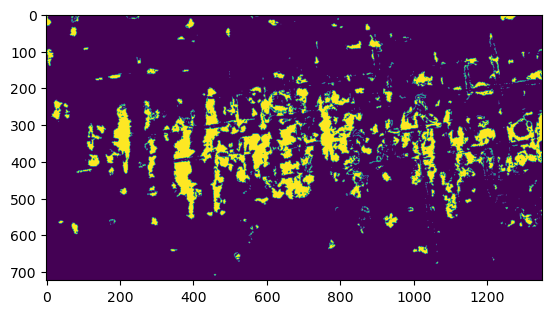

In [167]:
plt.imshow(CLgas_first<BPM_first)

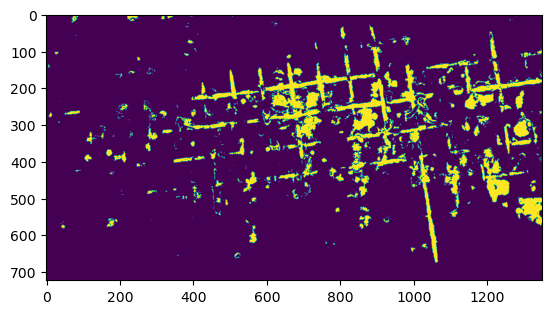

In [168]:
plt.imshow(CLgas_first>BPM_first)

### statistics

In [169]:
I_stat = np.arange(0,300,10)

In [170]:
CLhole_I_stat = np.histogram(-CLhole_I, bins=I_stat)
CLgas_I_stat = np.histogram(-CLgas_I, bins=I_stat)
BPM_I_stat = np.histogram(-BPM_I, bins=I_stat)

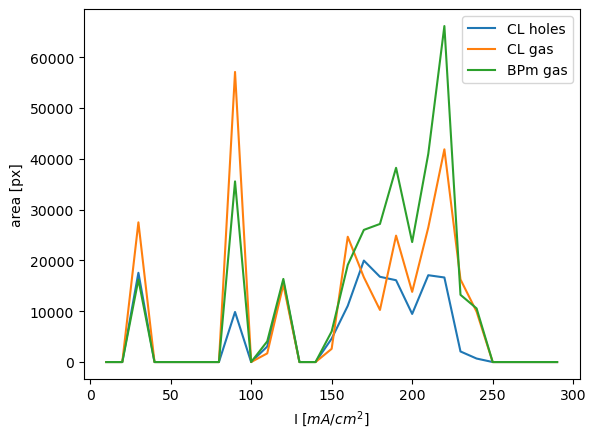

In [171]:
plt.plot(I_stat[1:], CLhole_I_stat[0],label='CL holes')
plt.plot(I_stat[1:], CLgas_I_stat[0],label='CL gas')
plt.plot(I_stat[1:], BPM_I_stat[0],  label='BPm gas')

plt.xlabel('I [$mA/cm^2$]')
plt.ylabel('area [px]')
plt.legend()

In [172]:
CLhole_I_stat

(array([    0,     0, 17580,     0,     0,     0,     0,     0,  9858,
            0,  3055, 15876,     0,     0,  4606, 11067, 19981, 16788,
        16112,  9472, 17099, 16652,  2082,   689,     0,     0,     0,
            0,     0]),
 array([  0,  10,  20,  30,  40,  50,  60,  70,  80,  90, 100, 110, 120,
        130, 140, 150, 160, 170, 180, 190, 200, 210, 220, 230, 240, 250,
        260, 270, 280, 290]))

In [ ]:
seg_data.coords['x1'] = np.arange(label_2.shape[0])
seg_data.coords['y1'] = np.arange(label_2.shape[1])
seg_data.coords['z1'] = np.arange(label_2.shape[2])
seg_data.attrs['comment'] = 'gas phases: 1 in gas phase is the membrane, 2 the gas between CL and memrbane'
seg_data.attrs['gas label gitsha'] = git_sha
seg_data['gas_phases'] = (['x1','y1','z1','timestep'], label_2)

In [ ]:
seg_data

In [ ]:
seg_data.to_netcdf(segpath)

In [ ]:
seg_data.close()

In [175]:
np.array(seg_data['gas_phases'].shape) -20

array([ 703,  107, 1330,   43])